# Práctica DL para Finanzas — Avance 2 (Capítulo 8)
**Redes neuronales, optimización y regularización: MLP y LSTM**

| Campo | Valor |
|---|---|
| Equipo | _Figueroa Manríquez Elizabeth Priscilla_ |
| Activo | BTC/USDT diario, MEXC spot (mismo archivo crudo del Avance 1) |
| Objetivo | $y_t = P_{t+1}/P_t - 1$ |
| Entradas | Los mismos 20 rendimientos rezagados del Avance 1 |
| Partición | La misma TR–VA–TE 70/15/15 por fecha objetivo. **TE no se usa.** |

Requisitos del Avance 2 que cubre este notebook:
1. MLP y LSTM con el mismo objetivo, variables y particiones, **entrenados en T4**. Para LSTM se verifica la forma *ejemplos × pasos temporales × variables*.
2. Registro de capas, neuronas, parámetros entrenables, pérdida, optimizador, tasa de aprendizaje, tamaño de lote y máximo de épocas.
3. Parada temprana con VA, restaurando los mejores pesos. Curvas de pérdida de TR y VA por época.
4. Tres configuraciones por red (solo cambia el número de neuronas), selección con RMSE de VA y repetición de la mejor con tres semillas (media y desviación estándar).
5. Comparación con los modelos del capítulo 7 y selección justificada con VA.
6. Pruebas controladas de errores (requisito transversal): conjunto vacío, fecha duplicada, valor no válido y dimensiones incorrectas.

**Antes de ejecutar:**
1. `Entorno de ejecución → Cambiar tipo de entorno → GPU T4`.
2. La carpeta `MyDrive/DL_Finanzas` del Avance 1 debe existir, con el archivo crudo en `datos/originales/`. Así se usan exactamente los mismos datos y fechas.
3. `Entorno de ejecución → Ejecutar todas`.

## 0. Entorno, configuración, versiones y bitácora

In [1]:
# === 0.1 Montar Drive y crear carpetas persistentes ===
import os, sys, json, time, random, hashlib, platform, subprocess, warnings
from datetime import datetime, timezone
from pathlib import Path

try:
    from google.colab import drive
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/DL_Finanzas')
else:
    BASE = Path(os.environ.get('DL_FIN_BASE', './DL_Finanzas'))

DIRS = {k: BASE / v for k, v in {
    'crudos': 'datos/originales',
    'procesados': 'datos/procesados',
    'modelos': 'modelos',
    'resultados': 'resultados',
    'figuras': 'figuras',
    'evidencia': 'evidencia_t4',
    'bitacora': 'bitacora',
}.items()}
for carpeta in DIRS.values():
    carpeta.mkdir(parents=True, exist_ok=True)
print('En Colab:', EN_COLAB)
print('Carpeta del proyecto:', BASE.resolve())

Mounted at /content/drive
En Colab: True
Carpeta del proyecto: /content/drive/MyDrive/DL_Finanzas


In [2]:
# === 0.2 Librerías, configuración, semilla y versiones ===
import numpy as np
import pandas as pd
import requests, joblib, sklearn, matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor

CONFIG = {
    # --- Datos y partición: idénticos al Avance 1 ---
    'MERCADO': 'Criptomonedas',
    'SIMBOLO': 'BTCUSDT',
    'MONEDA_BASE': 'BTC',
    'MONEDA_COTIZADA': 'USDT',
    'INTERVALO': '1d',
    'FUENTE': 'MEXC Spot API v3, endpoint público GET /api/v3/klines',
    'URL_KLINES': 'https://api.mexc.com/api/v3/klines',
    'INICIO_DESCARGA_UTC': '2017-01-01',
    'REUTILIZAR_CRUDO': True,      # usa el mismo crudo del Avance 1 (mismas fechas TR/VA/TE)
    'ARCHIVO_LOCAL': None,
    'MIN_OBS': 1500,
    'HUECO_MAX_DIAS': 7,
    'N_REZAGOS': 20,
    'PROP_TR': 0.70,
    'PROP_VA': 0.15,
    'SEMILLA': 42,
    # --- Redes del capítulo 8 ---
    'REQUIERE_T4': True,           # si no hay T4, se detiene el entrenamiento profundo (regla del protocolo)
    'PERDIDA': 'mean_squared_error',   # como en el libro
    'OPTIMIZADOR': 'Adam',             # como en el libro
    'TASA_APRENDIZAJE': 1e-3,
    'LOTE': 32,                    # el libro sugiere empezar con 32
    'MAX_EPOCAS': 300,
    'PACIENCIA': 25,               # épocas sin mejorar la pérdida de VA antes de detener
    'NEURONAS_CANDIDATAS': [10, 20, 40],   # 20 = configuración del libro; solo cambia el número de neuronas
    'SEMILLAS': [42, 123, 2024],   # repetición de la mejor configuración de cada red
    'MODELOS_COMPLEMENTARIOS_CAP8': True,  # RNN simple y CNN temporal del libro (opcional)
}
SEMILLA = CONFIG['SEMILLA']
random.seed(SEMILLA)
np.random.seed(SEMILLA)
os.environ['PYTHONHASHSEED'] = str(SEMILLA)

import tensorflow as tf
import keras
from keras import layers
info_build = tf.sysconfig.get_build_info()
VERSIONES = {
    'python': platform.python_version(),
    'numpy': np.__version__,
    'pandas': pd.__version__,
    'scikit-learn': sklearn.__version__,
    'matplotlib': matplotlib.__version__,
    'tensorflow': tf.__version__,
    'keras': keras.__version__,
    'cuda_build': info_build.get('cuda_version', 'n/d'),
    'cudnn_build': info_build.get('cudnn_version', 'n/d'),
    'plataforma': platform.platform(),
    'semilla_base': SEMILLA,
    'fecha_ejecucion_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
}
with open(DIRS['resultados'] / 'versiones_entorno_cap8.json', 'w') as f:
    json.dump(VERSIONES, f, indent=2)
pd.Series(VERSIONES)

,0
python,3.13.16
numpy,2.4.6
pandas,2.2.3
scikit-learn,1.6.1
matplotlib,3.10.0
tensorflow,2.21.0
keras,3.13.2
cuda_build,12.5.1
cudnn_build,9
plataforma,Linux-6.6.159+-x86_64-with-glibc2.39


In [3]:
# === 0.3 Excepciones específicas y bitácora de errores ===
# Regla: nada de "except: pass". Cada error se captura por tipo, se explica y se registra.
class ErrorPractica(Exception):
    'Error base de la práctica.'
class DescargaError(ErrorPractica):
    'La fuente no respondió o respondió con un error.'
class DatosVaciosError(ErrorPractica):
    'No hay datos, o no alcanzan el mínimo requerido.'
class FechaDuplicadaError(ErrorPractica):
    'Fechas repetidas que no se pueden resolver con la regla documentada.'
class ValorInvalidoError(ErrorPractica):
    'Valores no finitos, no positivos o archivo alterado.'
class DimensionError(ErrorPractica):
    'Formas o columnas distintas a las esperadas.'
class FugaInformacionError(ErrorPractica):
    'Se detectó uso de información futura o del conjunto reservado.'

RUTA_BITACORA = DIRS['bitacora'] / 'bitacora_errores.csv'

def registrar_evento(etapa, error, causa, accion, verificacion):
    'Agrega una fila: fecha | etapa | error | causa | acción correctiva | resultado de la verificación.'
    fila = pd.DataFrame([{
        'fecha': datetime.now(timezone.utc).isoformat(timespec='seconds'),
        'etapa': etapa, 'error': error, 'causa': causa,
        'accion_correctiva': accion, 'resultado_verificacion': verificacion,
    }])
    fila.to_csv(RUTA_BITACORA, mode='a', header=not RUTA_BITACORA.exists(), index=False)
    print(f'[BITÁCORA] {etapa} | {error} | {causa} | {accion} | {verificacion}')

In [4]:
# === 0.4 Excepciones adicionales del capítulo 8 ===
class ParticionDistintaError(ErrorPractica):
    'Las particiones no coinciden con las del Avance 1.'
class EntrenamientoError(ErrorPractica):
    'Fallo del entrenamiento (pérdida no finita, pesos no restaurados, GPU no usada).'

## 1. Evidencia de la GPU T4

Mismo procedimiento del Avance 1: `nvidia-smi`, TensorFlow reconoce la GPU y se ejecuta una operación en ella. Además, **cada entrenamiento registra el dispositivo donde quedaron los pesos, la memoria de GPU usada y el tiempo**.

In [5]:
# === 1. Evidencia de T4 ===
def verificar_t4():
    ts = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    ev = {'fecha_utc': ts, 'entorno_colab': EN_COLAB, 'semilla': SEMILLA}

    # 1) nvidia-smi
    try:
        salida = subprocess.run(['nvidia-smi'], capture_output=True, text=True,
                                timeout=30, check=True).stdout
        print(salida)
        (DIRS['evidencia'] / f'nvidia_smi_{ts}.txt').write_text(salida)
        consulta = subprocess.run(
            ['nvidia-smi', '--query-gpu=name,driver_version,memory.total', '--format=csv,noheader'],
            capture_output=True, text=True, timeout=30, check=True).stdout.strip()
        ev['nvidia_smi_gpu'] = consulta
    except FileNotFoundError:
        ev['nvidia_smi_gpu'] = 'nvidia-smi no existe: el entorno no tiene GPU NVIDIA'
    except subprocess.CalledProcessError as e:
        ev['nvidia_smi_gpu'] = f'nvidia-smi falló: {e.stderr.strip()}'
    except subprocess.TimeoutExpired:
        ev['nvidia_smi_gpu'] = 'nvidia-smi no respondió en 30 s'

    # 2) y 3) TensorFlow reconoce la GPU y ejecuta una operación en ella
    import tensorflow as tf
    tf.random.set_seed(SEMILLA)
    ev['tensorflow'] = tf.__version__
    ev['tf_construido_con_cuda'] = bool(tf.test.is_built_with_cuda())
    gpus = tf.config.list_physical_devices('GPU')
    ev['tf_gpus'] = [g.name for g in gpus]
    ev['operacion_dispositivo'] = 'sin GPU'
    if gpus:
        detalles = tf.config.experimental.get_device_details(gpus[0])
        ev['tf_nombre_gpu'] = detalles.get('device_name', '')
        ev['compute_capability'] = str(detalles.get('compute_capability', ''))
        with tf.device('/GPU:0'):
            a = tf.random.normal((4000, 4000))
            _ = tf.matmul(a, a).numpy()            # calentamiento
            t0 = time.perf_counter()
            c = tf.matmul(a, a)
            _ = c.numpy()                          # fuerza la sincronización
            ev['matmul_4000x4000_s'] = round(time.perf_counter() - t0, 4)
        ev['operacion_dispositivo'] = c.device
    nombre = f"{ev.get('tf_nombre_gpu', '')} {ev.get('nvidia_smi_gpu', '')}"
    ev['T4_OK'] = ('T4' in nombre) and ('GPU' in ev['operacion_dispositivo'])

    with open(DIRS['evidencia'] / f'evidencia_t4_{ts}.json', 'w') as f:
        json.dump(ev, f, indent=2)
    if not ev['T4_OK']:
        registrar_evento('entorno', 'T4 ausente o GPU no utilizada',
                         f"GPU detectada: {nombre.strip() or 'ninguna'}",
                         'Cap. 7 continúa en CPU (modelos clásicos). No entrenar MLP/LSTM; reprogramar sesión con T4.',
                         'pendiente')
    return ev

EVIDENCIA_T4 = verificar_t4()
print(json.dumps(EVIDENCIA_T4, indent=2))
print('\n>>> T4 verificada y usada por TensorFlow:', EVIDENCIA_T4['T4_OK'])

Thu Nov  5 23:44:43 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Datos y partición (mismo código y mismo archivo crudo del Avance 1)

Se vuelve a ejecutar la auditoría y la construcción de ventanas para que este notebook funcione solo desde una sesión limpia. Después se comprueba que las particiones coincidan exactamente con las del Avance 1.

In [6]:
# === 2. Descarga o carga del archivo crudo ===
COLS_MEXC = ['open_time', 'open', 'high', 'low', 'close', 'volume', 'close_time', 'quote_volume']
MS_DIA = 86_400_000

def sha256_archivo(ruta):
    h = hashlib.sha256()
    with open(ruta, 'rb') as f:
        for bloque in iter(lambda: f.read(1 << 20), b''):
            h.update(bloque)
    return h.hexdigest()

def _get_json(url, params, max_reintentos=5, espera_inicial=1.0):
    espera, ultimo_error = espera_inicial, None
    for intento in range(1, max_reintentos + 1):
        try:
            r = requests.get(url, params=params, timeout=20)
        except (requests.exceptions.Timeout, requests.exceptions.ConnectionError) as e:
            ultimo_error = f'{type(e).__name__}: {e}'
        else:
            if r.status_code == 429 or r.status_code >= 500:
                ultimo_error = f'HTTP {r.status_code}: {r.text[:200]}'
            elif r.status_code >= 400:
                raise DescargaError(f'MEXC rechazó la solicitud {params}: HTTP {r.status_code} {r.text[:300]}. '
                                    'Revise el símbolo (ej. BTCUSDT) y el intervalo (1d).')
            else:
                try:
                    return r.json()
                except ValueError as e:
                    raise DescargaError(f'MEXC no devolvió JSON válido: {r.text[:200]}') from e
        print(f'  intento {intento}/{max_reintentos} fallido ({ultimo_error}); nuevo intento en {espera:.0f} s')
        time.sleep(espera)
        espera *= 2
    raise DescargaError(f'Sin respuesta válida de MEXC tras {max_reintentos} intentos. Último error: {ultimo_error}')

def descargar_klines_mexc(simbolo, intervalo, inicio_utc, dias_por_bloque=200, pausa=0.25):
    # MEXC entrega como máximo ~500 velas por solicitud aunque se pidan 1000.
    # Por eso se piden bloques de 200 días y, si un bloque llega incompleto, se continúa desde la última vela recibida.
    ahora_ms = int(time.time() * 1000)
    s = int(pd.Timestamp(inicio_utc, tz='UTC').timestamp() * 1000)
    filas, solicitudes, incompletos = [], 0, []
    while s < ahora_ms:
        e = min(s + dias_por_bloque * MS_DIA - 1, ahora_ms)
        datos = _get_json(CONFIG['URL_KLINES'], {'symbol': simbolo, 'interval': intervalo,
                                                 'startTime': s, 'endTime': e, 'limit': 1000})
        solicitudes += 1
        if not isinstance(datos, list):
            raise DescargaError(f'MEXC devolvió un objeto inesperado (¿error?): {str(datos)[:300]}')
        if datos:
            filas.extend(datos)
            ultimo_open = max(int(k[0]) for k in datos)
            primero_open = min(int(k[0]) for k in datos)
            if filas and len(filas) > len(datos) and primero_open - s > 2 * MS_DIA:
                incompletos.append(f"{pd.to_datetime(s, unit='ms').date()}: faltan velas al inicio del bloque")
            siguiente = ultimo_open + MS_DIA          # continuar justo después de la última vela recibida
            if ultimo_open + MS_DIA <= e:
                print(f"  {pd.to_datetime(s, unit='ms').date()} → {pd.to_datetime(ultimo_open, unit='ms').date()}: "
                      f"{len(datos)} velas (bloque incompleto, se continúa desde ahí)")
            else:
                print(f"  {pd.to_datetime(s, unit='ms').date()} → {pd.to_datetime(e, unit='ms').date()}: {len(datos)} velas")
            s = max(siguiente, s + MS_DIA)
        else:
            s = e + 1
        time.sleep(pausa)
    if not filas:
        raise DatosVaciosError(f'MEXC no devolvió velas para {simbolo} {intervalo} desde {inicio_utc}. '
                               'Verifique que el par existe en MEXC spot y la conectividad.')
    if incompletos:
        print('ADVERTENCIA: posibles bloques truncados por la API:', incompletos)
    anchos = {len(f) for f in filas}
    if min(anchos) < 7:
        raise DimensionError(f'Velas con {sorted(anchos)} campos; se esperaban al menos 7 (open_time … close_time).')
    df = pd.DataFrame([f[:8] for f in filas])
    df.columns = COLS_MEXC[:df.shape[1]]
    return df, {'descarga_ms': ahora_ms, 'bloques': solicitudes, 'avisos_truncamiento': incompletos}

VERSION_DESCARGA = 2   # v2: bloques de 200 días con continuación; los crudos v1 (bloques de 1000 días) quedaron truncados

SIM, INTV = CONFIG['SIMBOLO'], CONFIG['INTERVALO']
ARCH_CRUDO = DIRS['crudos'] / f'{SIM}_{INTV}_mexc_crudo.csv'
ARCH_META = DIRS['crudos'] / f'{SIM}_{INTV}_mexc_crudo_meta.json'

META_PREVIA = json.load(open(ARCH_META)) if ARCH_META.exists() else {}
if META_PREVIA and META_PREVIA.get('version_descarga', 1) < VERSION_DESCARGA and not CONFIG['ARCHIVO_LOCAL']:
    print('El crudo guardado proviene de la descarga v1 (bloques truncados por MEXC): se descargará de nuevo y se respaldará el anterior.')
    registrar_evento('descarga', 'Crudo truncado por límite de velas de MEXC',
                     'La API devuelve ~500 velas por solicitud; bloques de 1000 días dejaron huecos de 500 días',
                     'Descarga v2: bloques de 200 días con continuación; crudo v1 respaldado', 'ver auditoría de la nueva descarga')
    usar_previo = False
else:
    usar_previo = True
if CONFIG['REUTILIZAR_CRUDO'] and usar_previo and ARCH_CRUDO.exists() and ARCH_META.exists():
    META = META_PREVIA
    if sha256_archivo(ARCH_CRUDO) != META['sha256']:
        raise ValorInvalidoError(f'{ARCH_CRUDO.name} no coincide con su SHA-256 registrado: el archivo crudo fue modificado. '
                                 'Restaure el original o descargue de nuevo con REUTILIZAR_CRUDO=False.')
    crudo = pd.read_csv(ARCH_CRUDO)
    print(f"Archivo crudo reutilizado: {ARCH_CRUDO.name} (descargado {META['fecha_descarga_utc']}), {len(crudo)} filas")
elif CONFIG['ARCHIVO_LOCAL']:
    ruta_local = Path(CONFIG['ARCHIVO_LOCAL'])
    if not ruta_local.exists():
        raise DatosVaciosError(f'La copia local {ruta_local} no existe.')
    crudo = pd.read_csv(ruta_local)
    crudo.to_csv(ARCH_CRUDO, index=False)
    META = {'fuente': f'Copia local identificada: {ruta_local}', 'simbolo': SIM, 'intervalo': INTV,
            'fecha_descarga_utc': datetime.fromtimestamp(ruta_local.stat().st_mtime, timezone.utc).isoformat(timespec='seconds'),
            'descarga_ms': int(ruta_local.stat().st_mtime * 1000),
            'filas_recibidas': len(crudo), 'sha256': sha256_archivo(ARCH_CRUDO)}
    with open(ARCH_META, 'w') as f:
        json.dump(META, f, indent=2)
    registrar_evento('descarga', 'Uso de copia local', 'Descarga no disponible',
                     f'Se cargó {ruta_local} y se registró su huella', 'trazabilidad conservada')
else:
    if ARCH_CRUDO.exists():  # respaldo: nunca se sobrescribe un crudo previo
        sello = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
        ARCH_CRUDO.rename(ARCH_CRUDO.with_name(f'{ARCH_CRUDO.stem}_respaldo_{sello}.csv'))
        if ARCH_META.exists():
            ARCH_META.rename(ARCH_META.with_name(f'{ARCH_META.stem}_respaldo_{sello}.json'))
    try:
        crudo, info = descargar_klines_mexc(SIM, INTV, CONFIG['INICIO_DESCARGA_UTC'])
    except (DescargaError, DatosVaciosError, DimensionError) as e:
        registrar_evento('descarga', type(e).__name__, f'{CONFIG["FUENTE"]} | {SIM} | {e}',
                         'Flujo detenido. Revisar conectividad/símbolo o usar ARCHIVO_LOCAL identificado.', 'sin datos')
        raise
    crudo.to_csv(ARCH_CRUDO, index=False)
    META = {'fuente': CONFIG['FUENTE'], 'url': CONFIG['URL_KLINES'], 'simbolo': SIM, 'intervalo': INTV,
            'parametros': {'startTime_inicial': CONFIG['INICIO_DESCARGA_UTC'], 'limit': 1000, 'dias_por_bloque': 200},
            'version_descarga': VERSION_DESCARGA, 'avisos_truncamiento': info['avisos_truncamiento'],
            'fecha_descarga_utc': datetime.fromtimestamp(info['descarga_ms'] / 1000, timezone.utc).isoformat(timespec='seconds'),
            'descarga_ms': info['descarga_ms'], 'bloques': info['bloques'],
            'filas_recibidas': len(crudo), 'columnas': list(crudo.columns),
            'zona_horaria': 'Marcas de tiempo en milisegundos Unix (UTC)',
            'sha256': sha256_archivo(ARCH_CRUDO)}
    with open(ARCH_META, 'w') as f:
        json.dump(META, f, indent=2)
    print(f'Crudo guardado: {ARCH_CRUDO} ({len(crudo)} filas)')

crudo.head()

Archivo crudo reutilizado: BTCUSDT_1d_mexc_crudo.csv (descargado 2026-11-05T14:21:43+00:00), 3298 filas


,open_time,open,high,low,close,volume,close_time,quote_volume
0,1508947200000,5712.00,5990.00,5400.00,5875.91,1489.138175,1509033600000,8.509059e+06
1,1509033600000,5876.00,5948.52,5669.93,5739.00,523.927660,1509120000000,3.066163e+06
2,1509120000000,5743.43,5791.80,5637.63,5658.62,304.100423,1509206400000,1.735743e+06
3,1509206400000,5656.46,5977.30,5648.03,5936.95,257.814473,1509292800000,1.474287e+06
4,1509292800000,5940.77,6215.80,5875.00,6076.90,272.660564,1509379200000,1.663914e+06


In [7]:
# === 3. Auditoría ===
def auditar(crudo, meta, min_obs, hueco_max):
    reg = []
    def anotar(control, filas, accion, detalle=''):
        reg.append({'control': control, 'filas_afectadas': int(filas), 'accion': accion, 'detalle': detalle})

    if crudo is None or crudo.empty:
        raise DatosVaciosError('El archivo crudo está vacío: no hay nada que auditar.')
    requeridas = ['open_time', 'open', 'high', 'low', 'close', 'close_time']
    faltan = [c for c in requeridas if c not in crudo.columns]
    if faltan:
        raise DimensionError(f'Faltan columnas {faltan}. Recibidas: {list(crudo.columns)}')

    df = crudo.copy()
    anotar('Filas recibidas', len(df), 'ninguna')

    num = [c for c in ['open', 'high', 'low', 'close', 'volume', 'quote_volume'] if c in df.columns]
    nan_antes = df[num].isna().sum()
    for c in num:
        df[c] = pd.to_numeric(df[c], errors='coerce')
    no_num = int((df[num].isna().sum() - nan_antes).sum())
    anotar('Valores no numéricos convertidos a NaN', no_num, 'se tratan como no válidos')
    df['open_time'] = pd.to_numeric(df['open_time'], errors='raise').astype('int64')
    df['close_time'] = pd.to_numeric(df['close_time'], errors='raise').astype('int64')

    abierta = df['close_time'] > meta['descarga_ms']
    anotar('Vela no cerrada al descargar', abierta.sum(), 'eliminada',
           ', '.join(pd.to_datetime(df.loc[abierta, 'open_time'], unit='ms').dt.strftime('%Y-%m-%d')))
    df = df.loc[~abierta].copy()

    fecha_utc = pd.to_datetime(df['open_time'], unit='ms', utc=True)
    horas = fecha_utc.dt.strftime('%H:%M UTC').value_counts()
    anotar('Hora de apertura de la vela diaria', 0, 'registrada', horas.to_dict().__repr__())
    df['fecha'] = fecha_utc.dt.tz_convert(None).dt.normalize()

    desorden = int((df['fecha'].diff().dt.total_seconds() < 0).sum())
    df = df.sort_values('fecha', kind='mergesort').reset_index(drop=True)
    anotar('Fechas fuera de orden', desorden, 'reordenadas cronológicamente')

    dup = df.duplicated('fecha', keep=False)
    if dup.any():
        precios_cols = ['open', 'high', 'low', 'close']
        conflicto = [f for f, g in df[dup].groupby('fecha') if (g[precios_cols].nunique() > 1).any()]
        if conflicto:
            raise FechaDuplicadaError(f'{len(conflicto)} fechas repetidas con precios distintos '
                                      f'(ej. {[str(x.date()) for x in conflicto[:3]]}). Revise la fuente; no se elige una al azar.')
    n_dup = int(df.duplicated('fecha').sum())
    df = df.drop_duplicates('fecha', keep='first').reset_index(drop=True)
    anotar('Fechas duplicadas idénticas', n_dup, 'se conservó la primera')

    precios = ['open', 'high', 'low', 'close']
    malos = (~np.isfinite(df[precios])).any(axis=1) | (df[precios] <= 0).any(axis=1)
    det = df.loc[malos, ['fecha'] + precios]
    anotar('Precios no finitos o no positivos', malos.sum(), 'fila retirada (sin imputar)',
           det.to_dict('records').__repr__()[:500])
    df = df.loc[~malos].reset_index(drop=True)

    if 'volume' in df.columns:
        anotar('Volumen faltante', df['volume'].isna().sum(), 'se conserva sin inventar')
        anotar('Volumen igual a cero', (df['volume'] == 0).sum(), 'se conserva; día sin negociación reportado')

    incoh = ((df['high'] < df[['open', 'close']].max(axis=1)) |
             (df['low'] > df[['open', 'close']].min(axis=1)) | (df['high'] < df['low']))
    anotar('Incoherencia OHLC', incoh.sum(), 'reportada, sin modificar',
           ', '.join(df.loc[incoh, 'fecha'].dt.strftime('%Y-%m-%d').head(10)))

    # Alineación uniforme: todas las velas deben cerrar a la misma hora UTC.
    # Mezclar cortes distintos produce "rendimientos diarios" de 16 o 32 horas.
    hora = pd.to_datetime(df['open_time'], unit='ms', utc=True).dt.strftime('%H:%M')
    hora_vigente = hora.iloc[-1]
    otra_hora = hora != hora_vigente
    anotar('Velas con otra hora de corte', otra_hora.sum(),
           f'retiradas: se conserva solo la alineación vigente ({hora_vigente} UTC)',
           (f"{df.loc[otra_hora, 'fecha'].min().date()} a {df.loc[otra_hora, 'fecha'].max().date()}" if otra_hora.any() else ''))
    df = df.loc[~otra_hora].reset_index(drop=True)

    # Bloque continuo más reciente: la historia separada por un hueco grande no se une ni se rellena.
    salto = df['fecha'].diff() > pd.Timedelta(days=hueco_max)
    if salto.any():
        inicio_bloque = df.loc[salto[salto].index[-1], 'fecha']
        previas = df['fecha'] < inicio_bloque
        anotar(f'Historia anterior a un hueco > {hueco_max} días', previas.sum(),
               f'retirada: se usa el bloque desde {inicio_bloque.date()}',
               f"{df.loc[previas, 'fecha'].min().date()} a {df.loc[previas, 'fecha'].max().date()}")
        df = df.loc[~previas].reset_index(drop=True)

    rango = pd.date_range(df['fecha'].min(), df['fecha'].max(), freq='D')
    faltantes = rango.difference(df['fecha'])
    anotar('Días faltantes en calendario continuo', len(faltantes), 'no se rellenan',
           ', '.join(faltantes.strftime('%Y-%m-%d')[:20]))

    r = df['close'] / df['close'].shift(1) - 1
    med = r.median()
    mad = (r - med).abs().median()
    z = 0.6745 * (r - med) / mad if mad > 0 else pd.Series(0.0, index=r.index)
    ext = df.loc[z.abs() > 6, ['fecha']].assign(rendimiento=r[z.abs() > 6].round(4))
    anotar('Rendimientos extremos (|z robusto| > 6)', len(ext), 'marcados, no eliminados',
           ext.astype(str).to_dict('records').__repr__()[:500])

    if len(df) < min_obs:
        raise DatosVaciosError(f'Solo hay {len(df)} observaciones válidas; el protocolo exige ≥ {min_obs}. '
                               'Elija un activo con más historia o revise la descarga.')
    anotar('Observaciones válidas finales', len(df), f'cumple mínimo de {min_obs}')

    cols = ['fecha', 'open', 'high', 'low', 'close'] + [c for c in ['volume', 'quote_volume'] if c in df.columns] + ['open_time', 'close_time']
    return df[cols], pd.DataFrame(reg), faltantes, ext

try:
    datos, AUDITORIA, FALTANTES, EXTREMOS = auditar(crudo, META, CONFIG['MIN_OBS'], CONFIG['HUECO_MAX_DIAS'])
except (DatosVaciosError, DimensionError, FechaDuplicadaError) as e:
    registrar_evento('auditoría', type(e).__name__, str(e), 'Flujo detenido antes de construir ventanas', 'pendiente')
    raise

AUDITORIA.to_csv(DIRS['resultados'] / 'auditoria_datos.csv', index=False)
ARCH_PROC = DIRS['procesados'] / f'{SIM}_{INTV}_procesado.csv'
datos.to_csv(ARCH_PROC, index=False)
print(f'Procesado guardado: {ARCH_PROC}  |  {datos.fecha.min().date()} → {datos.fecha.max().date()}  |  {len(datos)} días')
pd.set_option('display.max_colwidth', 120)
AUDITORIA

Procesado guardado: /content/drive/MyDrive/DL_Finanzas/datos/procesados/BTCUSDT_1d_procesado.csv  |  2018-08-23 → 2026-11-04  |  2995 días


,control,filas_afectadas,accion,detalle
0,Filas recibidas,3298,ninguna,
1,Valores no numéricos convertidos a NaN,0,se tratan como no válidos,
2,Vela no cerrada al descargar,1,eliminada,2026-11-05
3,Hora de apertura de la vela diaria,0,registrada,"{'00:00 UTC': 2995, '16:00 UTC': 302}"
4,Fechas fuera de orden,0,reordenadas cronológicamente,
5,Fechas duplicadas idénticas,0,se conservó la primera,
6,Precios no finitos o no positivos,0,fila retirada (sin imputar),[]
7,Volumen faltante,0,se conserva sin inventar,
8,Volumen igual a cero,0,se conserva; día sin negociación reportado,
9,Incoherencia OHLC,0,"reportada, sin modificar",


In [8]:
# === 5. Objetivo y ventanas ===
N = CONFIG['N_REZAGOS']
UN_DIA = pd.Timedelta(days=1)
FEATS = [f'ret_lag_{k}' for k in range(N)]

d = datos[['fecha', 'close']].copy().reset_index(drop=True)
d['ret'] = d['close'] / d['close'].shift(1) - 1
d['ret_consecutivo'] = d['fecha'].diff() == UN_DIA
d['fecha_objetivo'] = d['fecha'].shift(-1)
d['close_siguiente'] = d['close'].shift(-1)
d['y'] = d['close_siguiente'] / d['close'] - 1
d['objetivo_valido'] = (d['fecha_objetivo'] - d['fecha']) == UN_DIA
for k in range(N):
    d[f'ret_lag_{k}'] = d['ret'].shift(k)
d['ventana_valida'] = d['ret_consecutivo'].astype(int).rolling(N).sum() == N
d['fecha_primer_cierre'] = d['fecha'].shift(N)

finitas = np.isfinite(d[FEATS + ['y']]).all(axis=1)
validas = d['objetivo_valido'] & d['ventana_valida'] & finitas
motivos = pd.Series({
    'filas procesadas': len(d),
    'sin objetivo observable o que cruza un hueco': int((~d['objetivo_valido']).sum()),
    'ventana incompleta (inicio de la serie o hueco)': int((~d['ventana_valida']).sum()),
    'ejemplos válidos': int(validas.sum()),
})
print(motivos.to_string())

ds = (d.loc[validas, ['fecha_primer_cierre', 'fecha', 'fecha_objetivo'] + FEATS + ['y', 'close', 'close_siguiente']]
        .rename(columns={'fecha': 'fecha_emision'})
        .sort_values('fecha_objetivo').reset_index(drop=True))

if not ds['fecha_objetivo'].is_unique or not ds['fecha_objetivo'].is_monotonic_increasing:
    raise FechaDuplicadaError('Las fechas objetivo no son únicas o no están ordenadas.')
if not ((ds['fecha_objetivo'] - ds['fecha_emision']) == UN_DIA).all():
    raise FugaInformacionError('Hay ejemplos cuyo objetivo no es el siguiente día.')
ds.head(3)

filas procesadas                                   2995
sin objetivo observable o que cruza un hueco          2
ventana incompleta (inicio de la serie o hueco)      40
ejemplos válidos                                   2953


,fecha_primer_cierre,fecha_emision,fecha_objetivo,ret_lag_0,ret_lag_1,ret_lag_2,ret_lag_3,ret_lag_4,ret_lag_5,ret_lag_6,...,ret_lag_13,ret_lag_14,ret_lag_15,ret_lag_16,ret_lag_17,ret_lag_18,ret_lag_19,y,close,close_siguiente
0,2018-08-23,2018-09-12,2018-09-13,0.007041,-0.002779,0.010525,0.009942,-0.033218,-0.018608,-0.028366,...,-0.007282,-0.005983,0.024298,0.030728,-0.004027,0.006264,0.025261,0.023106,6337.74,6484.18
1,2018-08-24,2018-09-13,2018-09-14,0.023106,0.007041,-0.002779,0.010525,0.009942,-0.033218,-0.018608,...,0.004141,-0.007282,-0.005983,0.024298,0.030728,-0.004027,0.006264,0.001966,6484.18,6496.93
2,2018-08-25,2018-09-14,2018-09-15,0.001966,0.023106,0.007041,-0.002779,0.010525,0.009942,-0.033218,...,0.026940,0.004141,-0.007282,-0.005983,0.024298,0.030728,-0.004027,0.003357,6496.93,6518.74


In [9]:
# === 6. Partición ===
n = len(ds)
n_tr = int(np.floor(n * CONFIG['PROP_TR']))
n_va = int(np.floor(n * CONFIG['PROP_VA']))
n_te = n - n_tr - n_va
if min(n_tr, n_va, n_te) <= 0:
    raise DimensionError(f'Partición vacía: TR={n_tr}, VA={n_va}, TE={n_te}. Revise el número de ejemplos ({n}).')
ds['conjunto'] = ['TR'] * n_tr + ['VA'] * n_va + ['TE'] * n_te
TR, VA, TE = (ds[ds.conjunto == c].reset_index(drop=True) for c in ('TR', 'VA', 'TE'))

# Comprobaciones obligatorias del protocolo
if not TR['fecha_objetivo'].max() < VA['fecha_objetivo'].min():
    raise FugaInformacionError('El último objetivo de TR no es anterior al primero de VA.')
if not VA['fecha_objetivo'].max() < TE['fecha_objetivo'].min():
    raise FugaInformacionError('El último objetivo de VA no es anterior al primero de TE.')
print('✔ último objetivo TR < primer objetivo VA')
print('✔ último objetivo VA < primer objetivo TE')

PARTICIONES = pd.DataFrame([{
    'conjunto': nombre, 'n_ejemplos': len(p), 'proporcion': round(len(p) / n, 4),
    'primera_emision': p.fecha_emision.min().date(), 'ultima_emision': p.fecha_emision.max().date(),
    'primer_objetivo': p.fecha_objetivo.min().date(), 'ultimo_objetivo': p.fecha_objetivo.max().date(),
    'primer_cierre_usado_como_contexto': p.fecha_primer_cierre.min().date(),
} for nombre, p in (('TR', TR), ('VA', VA), ('TE', TE))])
ARCH_PART7 = DIRS['resultados'] / 'particiones.csv'
if ARCH_PART7.exists():
    p7 = pd.read_csv(ARCH_PART7)
    p8 = PARTICIONES.astype(str)
    cols = ['conjunto', 'n_ejemplos', 'primer_objetivo', 'ultimo_objetivo']
    if not p7[cols].astype(str).reset_index(drop=True).equals(p8[cols].reset_index(drop=True)):
        registrar_evento('partición', 'Particiones distintas al Avance 1', 'Cambió el archivo crudo o la configuración',
                         'Detenido: restaurar el crudo del Avance 1 (verificado por SHA-256)', 'pendiente')
        raise ParticionDistintaError(f'Las particiones no coinciden con las del Avance 1.\nAvance 1:\n{p7[cols]}\nAhora:\n{p8[cols]}')
    print('✔ Particiones idénticas a las del Avance 1 (tamaños y fechas)')
    PARTICION_VERIFICADA = True
else:
    print('Aviso: no se encontró particiones.csv del Avance 1; se guarda la partición actual.')
    PARTICION_VERIFICADA = False
    PARTICIONES.to_csv(ARCH_PART7, index=False)
ds.to_csv(DIRS['procesados'] / f'{SIM}_{INTV}_ejemplos_ventanas.csv', index=False)
PARTICIONES

✔ último objetivo TR < primer objetivo VA
✔ último objetivo VA < primer objetivo TE
✔ Particiones idénticas a las del Avance 1 (tamaños y fechas)


,conjunto,n_ejemplos,proporcion,primera_emision,ultima_emision,primer_objetivo,ultimo_objetivo,primer_cierre_usado_como_contexto
0,TR,2067,0.7000,2018-09-12,2024-05-31,2018-09-13,2024-06-01,2018-08-23
1,VA,442,0.1497,2024-06-01,2025-08-16,2024-06-02,2025-08-17,2024-05-12
2,TE,444,0.1504,2025-08-17,2026-11-03,2025-08-18,2026-11-04,2025-07-28


In [10]:
# === 7. Escalador ===
X_tr, y_tr = TR[FEATS].to_numpy(float), TR['y'].to_numpy(float)
X_va, y_va = VA[FEATS].to_numpy(float), VA['y'].to_numpy(float)
X_te, y_te = TE[FEATS].to_numpy(float), TE['y'].to_numpy(float)   # TE reservado: no se predice en el cap. 7

for nombre, X, y in (('TR', X_tr, y_tr), ('VA', X_va, y_va), ('TE', X_te, y_te)):
    if X.ndim != 2 or X.shape[1] != N or len(X) != len(y):
        raise DimensionError(f'{nombre}: forma esperada (ejemplos, {N}) con y del mismo largo; recibida X={X.shape}, y={y.shape}')
    if not (np.isfinite(X).all() and np.isfinite(y).all()):
        raise ValorInvalidoError(f'{nombre} contiene valores no finitos.')

escalador = StandardScaler().fit(X_tr)          # ← único ajuste
if escalador.n_samples_seen_ != len(X_tr):
    raise FugaInformacionError('El escalador vio un número de filas distinto a TR.')
X_tr_e, X_va_e, X_te_e = (escalador.transform(X) for X in (X_tr, X_va, X_te))
joblib.dump(escalador, DIRS['modelos'] / 'escalador_cap7_rezagos20.joblib')

print(f'Escalador ajustado con {int(escalador.n_samples_seen_)} filas de TR (= len(TR) = {len(TR)})')
print(f'Media de TR escalado  ≈ {X_tr_e.mean():+.2e}   (≈ 0 por construcción)')
print(f'Media de VA escalado  = {X_va_e.mean():+.4f}   (no es 0: no se reajustó con VA)')

Escalador ajustado con 2067 filas de TR (= len(TR) = 2067)
Media de TR escalado  ≈ +3.78e-18   (≈ 0 por construcción)
Media de VA escalado  = -0.0038   (no es 0: no se reajustó con VA)


## 3. Pruebas controladas de errores (requisito transversal)

El protocolo pide provocar cuatro fallos **en copias pequeñas de los datos**, sin tocar los originales, y mostrar la detención o recuperación esperada. Cada prueba queda registrada en la bitácora.

In [11]:
# === 3. Pruebas controladas de errores ===
def verificar_formas(nombre, X, y, forma_esperada):
    'Detiene antes de entrenar si la forma no es la esperada. forma_esperada usa None para el número de ejemplos.'
    X, y = np.asarray(X), np.asarray(y)
    if len(X) == 0 or len(y) == 0:
        raise DatosVaciosError(f'{nombre}: el conjunto está vacío (X={X.shape}, y={y.shape}).')
    if X.ndim != len(forma_esperada) or any(e is not None and r != e for r, e in zip(X.shape, forma_esperada)):
        esperada = '(' + ', '.join('ejemplos' if e is None else str(e) for e in forma_esperada) + ')'
        raise DimensionError(f'{nombre}: forma esperada {esperada}, recibida {X.shape}. '
                             'Revise el número de rezagos y el reshape (ejemplos × pasos × variables para LSTM).')
    if len(X) != len(y):
        raise DimensionError(f'{nombre}: {len(X)} ejemplos en X y {len(y)} en y.')
    if not (np.isfinite(X).all() and np.isfinite(y).all()):
        raise ValorInvalidoError(f'{nombre}: hay valores no finitos; revise la auditoría y el escalado.')

COPIA = crudo.iloc[-160:-10].copy()      # copia pequeña de velas recientes; el original no se modifica
SHA_ANTES = sha256_archivo(ARCH_CRUDO)
PRUEBAS = []

def probar(nombre, funcion, error_esperado=None, verificacion=None):
    try:
        resultado = funcion()
    except error_esperado if error_esperado else () as e:
        msg = f'{type(e).__name__}: {e}'
        PRUEBAS.append({'prueba': nombre, 'respuesta': 'detención', 'mensaje': msg[:220], 'correcto': True})
        registrar_evento('prueba controlada', nombre, 'fallo provocado en copia pequeña', 'el flujo se detuvo con mensaje', 'OK')
        return
    if error_esperado:
        PRUEBAS.append({'prueba': nombre, 'respuesta': 'NO se detuvo', 'mensaje': '', 'correcto': False})
        registrar_evento('prueba controlada', nombre, 'fallo provocado en copia pequeña', 'no se detectó', 'FALLÓ: revisar controles')
        return
    ok, msg = verificacion(resultado)
    PRUEBAS.append({'prueba': nombre, 'respuesta': 'recuperación', 'mensaje': msg[:220], 'correcto': ok})
    registrar_evento('prueba controlada', nombre, 'fallo provocado en copia pequeña', msg[:120], 'OK' if ok else 'FALLÓ')

# 1) Conjunto vacío → la auditoría se detiene
probar('1. Conjunto vacío', lambda: auditar(COPIA.iloc[0:0], META, 50, CONFIG['HUECO_MAX_DIAS']), DatosVaciosError)

# 2) Fecha duplicada con precios distintos → se detiene (no se elige una fila al azar)
dup = COPIA.iloc[[60]].copy()
dup['close'] = pd.to_numeric(dup['close']) * 1.05
probar('2. Fecha duplicada', lambda: auditar(pd.concat([COPIA, dup]), META, 50, CONFIG['HUECO_MAX_DIAS']), FechaDuplicadaError)

# 3) Valor no válido (precio negativo e infinito) → la regla documentada retira esas filas sin imputar
malo = COPIA.copy()
malo['close'] = pd.to_numeric(malo['close']).astype(float)
malo.iloc[40, malo.columns.get_loc('close')] = -5.0
malo.iloc[41, malo.columns.get_loc('close')] = np.inf
def _verif_invalidos(res):
    df_ok, aud, *_ = res
    n = int(aud.loc[aud.control == 'Precios no finitos o no positivos', 'filas_afectadas'].iloc[0])
    limpio = np.isfinite(df_ok[['open', 'high', 'low', 'close']]).all().all() and (df_ok['close'] > 0).all()
    return (n == 2 and limpio), f'{n} filas retiradas; datos resultantes finitos y positivos: {limpio}'
probar('3. Valor no válido', lambda: auditar(malo, META, 50, CONFIG['HUECO_MAX_DIAS']), None, _verif_invalidos)

# 4) Dimensiones incorrectas → se detiene antes de entrenar
probar('4a. Dimensiones incorrectas (MLP con 19 rezagos)',
       lambda: verificar_formas('MLP', X_tr_e[:50, :19], y_tr[:50], (None, CONFIG['N_REZAGOS'])), DimensionError)
probar('4b. Dimensiones incorrectas (LSTM sin eje de variables)',
       lambda: verificar_formas('LSTM', X_tr_e[:50], y_tr[:50], (None, CONFIG['N_REZAGOS'], 1)), DimensionError)

if sha256_archivo(ARCH_CRUDO) != SHA_ANTES:
    raise ValorInvalidoError('Las pruebas modificaron el archivo crudo original.')
PRUEBAS_DF = pd.DataFrame(PRUEBAS)
PRUEBAS_DF.to_csv(DIRS['resultados'] / 'pruebas_controladas_errores.csv', index=False)
print('✔ El archivo crudo original no cambió (SHA-256 idéntico).')
if not PRUEBAS_DF['correcto'].all():
    raise ErrorPractica('Alguna prueba controlada no respondió como se esperaba; revisar antes de entrenar.')
PRUEBAS_DF

[BITÁCORA] prueba controlada | 1. Conjunto vacío | fallo provocado en copia pequeña | el flujo se detuvo con mensaje | OK
[BITÁCORA] prueba controlada | 2. Fecha duplicada | fallo provocado en copia pequeña | el flujo se detuvo con mensaje | OK
[BITÁCORA] prueba controlada | 3. Valor no válido | fallo provocado en copia pequeña | 2 filas retiradas; datos resultantes finitos y positivos: True | OK
[BITÁCORA] prueba controlada | 4a. Dimensiones incorrectas (MLP con 19 rezagos) | fallo provocado en copia pequeña | el flujo se detuvo con mensaje | OK
[BITÁCORA] prueba controlada | 4b. Dimensiones incorrectas (LSTM sin eje de variables) | fallo provocado en copia pequeña | el flujo se detuvo con mensaje | OK
✔ El archivo crudo original no cambió (SHA-256 idéntico).


,prueba,respuesta,mensaje,correcto
0,1. Conjunto vacío,detención,DatosVaciosError: El archivo crudo está vacío: no hay nada que auditar.,True
1,2. Fecha duplicada,detención,FechaDuplicadaError: 1 fechas repetidas con precios distintos (ej. ['2026-07-29']). Revise la fuente; no se elige un...,True
2,3. Valor no válido,recuperación,2 filas retiradas; datos resultantes finitos y positivos: True,True
3,4a. Dimensiones incorrectas (MLP con 19 rezagos),detención,"DimensionError: MLP: forma esperada (ejemplos, 20), recibida (50, 19). Revise el número de rezagos y el reshape (eje...",True
4,4b. Dimensiones incorrectas (LSTM sin eje de variables),detención,"DimensionError: LSTM: forma esperada (ejemplos, 20, 1), recibida (50, 20). Revise el número de rezagos y el reshape ...",True


## 4. Preparación de las entradas de las redes

- **Mismas variables y particiones que el capítulo 7:** 20 rezagos de rendimiento, estandarizados con el escalador ajustado solo en TR.
- **MLP:** recibe los 20 rezagos como un vector, forma *(ejemplos, 20)*.
- **LSTM:** recibe una secuencia ordenada del rendimiento más antiguo al más reciente ($r_{t-19}, \dots, r_t$), forma *(ejemplos, 20 pasos, 1 variable)*.
- **Objetivo:** también se estandariza con la media y desviación de TR, porque los rendimientos diarios son números muy pequeños. Las predicciones se regresan a la escala original antes de calcular las métricas. El libro no escala $y$; aquí se hace solo para estabilizar el entrenamiento.

In [12]:
# === 4. Entradas para MLP y LSTM ===
N = CONFIG['N_REZAGOS']
escalador_y = StandardScaler().fit(y_tr.reshape(-1, 1))          # ajustado solo con TR
if escalador_y.n_samples_seen_ != len(y_tr):
    raise FugaInformacionError('El escalador de y vio filas fuera de TR.')
a_escala_y = lambda v: escalador_y.transform(np.asarray(v).reshape(-1, 1)).ravel()
a_rendimiento = lambda v: escalador_y.inverse_transform(np.asarray(v).reshape(-1, 1)).ravel()
joblib.dump(escalador_y, DIRS['modelos'] / 'escalador_y_cap8.joblib')
y_tr_s, y_va_s = a_escala_y(y_tr), a_escala_y(y_va)

def a_secuencia(X):
    'Columnas ret_lag_0..ret_lag_19 (reciente→antiguo) a secuencia antiguo→reciente con 1 variable.'
    return np.ascontiguousarray(X[:, ::-1]).reshape(-1, X.shape[1], 1).astype('float32')

ENTRADAS = {
    'mlp':  {'TR': X_tr_e.astype('float32'), 'VA': X_va_e.astype('float32'), 'forma': (None, N)},
    'lstm': {'TR': a_secuencia(X_tr_e), 'VA': a_secuencia(X_va_e), 'forma': (None, N, 1)},
}
ENTRADAS['rnn'] = ENTRADAS['lstm']
ENTRADAS['cnn'] = ENTRADAS['lstm']

for red in ('mlp', 'lstm'):
    for conj, y_c in (('TR', y_tr_s), ('VA', y_va_s)):
        verificar_formas(f'{red.upper()} {conj}', ENTRADAS[red][conj], y_c, ENTRADAS[red]['forma'])
    print(f"{red.upper():4s}  TR {ENTRADAS[red]['TR'].shape}   VA {ENTRADAS[red]['VA'].shape}")

# Comprobación del orden temporal de la secuencia LSTM con el primer ejemplo de VA
seq = ENTRADAS['lstm']['VA'][0, :, 0]
ultimo = escalador.transform(X_va[:1])[0]
if not (np.isclose(seq[-1], ultimo[0]) and np.isclose(seq[0], ultimo[N - 1])):
    raise DimensionError('La secuencia LSTM no está ordenada de antiguo a reciente.')
print('✔ LSTM: forma ejemplos × pasos temporales × variables, y el último paso es el rendimiento más reciente (r_t).')

MLP   TR (2067, 20)   VA (442, 20)
LSTM  TR (2067, 20, 1)   VA (442, 20, 1)
✔ LSTM: forma ejemplos × pasos temporales × variables, y el último paso es el rendimiento más reciente (r_t).


## 5. Modelos de referencia del capítulo 7 (para comparar)

Se recalculan el pronóstico cero y la regresión lineal con los mismos datos (son deterministas y rápidos). Los modelos complementarios del capítulo 7 se leen de `experimentos.csv` si existen.

In [13]:
# === 5. Métricas y referencias ===
def precision_direccional(y, yhat):
    sy, sp = np.sign(y), np.sign(yhat)
    m = (sy != 0) & (sp != 0)
    return (float((sy[m] == sp[m]).mean()) if m.any() else np.nan), int(m.sum())

def model_bias(yhat):
    alcistas, bajistas = int((yhat > 0).sum()), int((yhat < 0).sum())
    return (alcistas / bajistas if bajistas > 0 else np.nan), alcistas, bajistas

def correlacion(y, yhat):
    return float(np.corrcoef(y, yhat)[0, 1]) if np.ptp(yhat) > 0 and np.ptp(y) > 0 else np.nan

def metricas(y, yhat):
    y, yhat = np.asarray(y, float).ravel(), np.asarray(yhat, float).ravel()
    if y.shape != yhat.shape:
        raise DimensionError(f'y {y.shape} y predicción {yhat.shape} tienen formas distintas.')
    if len(y) == 0:
        raise DatosVaciosError('No hay ejemplos para evaluar.')
    if not np.isfinite(yhat).all():
        raise ValorInvalidoError('Predicciones no finitas: revisar escalas, datos e hiperparámetros.')
    e = yhat - y
    pdir, ndir = precision_direccional(y, yhat)
    mb, alc, baj = model_bias(yhat)
    return {'MAE': float(np.mean(np.abs(e))), 'RMSE': float(np.sqrt(np.mean(e ** 2))),
            'prec_direccional': pdir, 'n_direccional': ndir, 'correlacion': correlacion(y, yhat),
            'model_bias': mb, 'senales_alcistas': alc, 'senales_bajistas': baj, 'n': len(y)}

RUTA_EXP = DIRS['resultados'] / 'experimentos.csv'
def registrar_experimentos(filas):
    nuevo = pd.DataFrame(filas)
    if RUTA_EXP.exists():
        prev = pd.read_csv(RUTA_EXP)
        clave_n = set(zip(nuevo['id'], nuevo['conjunto']))
        prev = prev[[(i, c) not in clave_n for i, c in zip(prev['id'], prev['conjunto'])]]
        nuevo = pd.concat([prev, nuevo], ignore_index=True)
    nuevo.to_csv(RUTA_EXP, index=False)

REALES = {'TR': (TR, y_tr), 'VA': (VA, y_va)}
REFERENCIAS = {}
for nombre, modelo in [('cero', DummyRegressor(strategy='constant', constant=0.0)),
                       ('regresion_lineal', LinearRegression())]:
    modelo.fit(X_tr_e, y_tr)
    REFERENCIAS[nombre] = {c: metricas(REALES[c][1], modelo.predict(X)) for c, X in (('TR', X_tr_e), ('VA', X_va_e))}
REF_VA = pd.DataFrame({k: v['VA'] for k, v in REFERENCIAS.items()}).T
print('Referencias recalculadas (VA):')
print(REF_VA[['MAE', 'RMSE', 'prec_direccional']].round(6).to_string())

META_PATH = DIRS['resultados'] / 'meta_para_dl.json'
if META_PATH.exists():
    META_DL = json.load(open(META_PATH))
    if not np.isclose(META_DL['RMSE_VA_regresion_lineal'], REF_VA.loc['regresion_lineal', 'RMSE'], rtol=1e-6):
        raise ParticionDistintaError('La regresión lineal no reproduce el RMSE de VA del Avance 1: revisar datos y partición.')
    print('\n✔ Las referencias reproducen exactamente los valores del Avance 1.')

Referencias recalculadas (VA):
                       MAE      RMSE  prec_direccional
cero              0.017219  0.024342               NaN
regresion_lineal  0.017276  0.024258          0.502262

✔ Las referencias reproducen exactamente los valores del Avance 1.


## 6. Arquitecturas del capítulo 8 y rutina de entrenamiento en T4

| Red | Arquitectura (como en el libro) |
|---|---|
| **MLP** | Entrada (20) → Dense(*n*, ReLU) → Dense(*n*, ReLU) → Dense(1) |
| **LSTM** | Entrada (20 pasos, 1 variable) → LSTM(*n*) → Dense(*n*, ReLU) → Dense(1) |

- Pérdida MSE y optimizador Adam, como en el libro. La tasa de aprendizaje, el lote y el máximo de épocas se registran en `experimentos.csv`.
- **Parada temprana:** monitorea la pérdida de VA y restaura los mejores pesos. Después se verifica que los pesos restaurados reproducen la mejor pérdida de VA.
- **Checkpoint:** el mejor modelo se guarda en Drive durante el entrenamiento (`modelos/cap8/`). El historial por época se guarda como CSV.
- **Dispositivo efectivo:** el entrenamiento se fuerza en `/GPU:0`. Se registran el dispositivo de los pesos, la memoria pico de GPU y el tiempo de cada corrida.
- **Errores:**
  - Pérdida no finita: `TerminateOnNaN`, entrenamiento detenido y registro en la bitácora.
  - Memoria insuficiente: se registra, se reduce el lote a la mitad y se reintenta.
  - Sin T4: no se entrena.

In [14]:
# === 6. Rutina de entrenamiento ===
if not EVIDENCIA_T4.get('T4_OK'):
    if CONFIG['REQUIERE_T4']:
        raise ErrorPractica('No hay T4 verificada: el protocolo exige detener el entrenamiento profundo. '
                            'El incidente ya quedó en la bitácora. Cambie el entorno a GPU T4 y vuelva a ejecutar.')
    print('AVISO: entrenamiento en CPU solo para probar el código; NO cuenta como evidencia del protocolo.')
DISPOSITIVO = '/GPU:0' if tf.config.list_physical_devices('GPU') else '/CPU:0'
GPU_NOMBRE = EVIDENCIA_T4.get('tf_nombre_gpu', 'sin GPU')
DIR_MOD8 = DIRS['modelos'] / 'cap8'
DIR_HIST = DIRS['resultados'] / 'historias_cap8'
DIR_MOD8.mkdir(parents=True, exist_ok=True)
DIR_HIST.mkdir(parents=True, exist_ok=True)

def construir_modelo(red, neuronas, tasa):
    if red == 'mlp':
        entrada = keras.Input(shape=(N,), name='rezagos')
        x = layers.Dense(neuronas, activation='relu', name='oculta_1')(entrada)
        x = layers.Dense(neuronas, activation='relu', name='oculta_2')(x)
    elif red == 'lstm':
        entrada = keras.Input(shape=(N, 1), name='secuencia')
        x = layers.LSTM(neuronas, name='lstm')(entrada)
        x = layers.Dense(neuronas, activation='relu', name='densa')(x)
    elif red == 'rnn':
        entrada = keras.Input(shape=(N, 1), name='secuencia')
        x = layers.SimpleRNN(neuronas, name='rnn')(entrada)
        x = layers.Dense(neuronas, activation='relu', name='densa')(x)
    elif red == 'cnn':
        entrada = keras.Input(shape=(N, 1), name='secuencia')
        x = layers.Conv1D(filters=neuronas, kernel_size=4, activation='relu', name='conv1d')(entrada)
        x = layers.MaxPooling1D(pool_size=2, name='maxpool')(x)
        x = layers.Flatten(name='aplanar')(x)
    else:
        raise ValueError(f'Red desconocida: {red}')
    salida = layers.Dense(1, name='salida')(x)
    modelo = keras.Model(entrada, salida, name=red)
    modelo.compile(optimizer=keras.optimizers.Adam(learning_rate=tasa), loss=CONFIG['PERDIDA'])
    return modelo

def dispositivo_de(variable):
    'Dispositivo donde vive un peso (Keras 3 envuelve la variable de TensorFlow en .value).'
    for cand in (getattr(variable, 'value', None), variable):
        d = getattr(cand, 'device', None)
        if d:
            return d
    return 'desconocido'

def describir_capas(modelo):
    partes = []
    for capa in modelo.layers[1:]:
        cfg = capa.get_config()
        detalle = cfg.get('units', cfg.get('filters', ''))
        act = cfg.get('activation', '')
        partes.append(f"{type(capa).__name__}({detalle}{', ' + act if act and act != 'linear' else ''})")
    return ' → '.join(partes)

def _entrenar_una_vez(red, neuronas, semilla, tasa, lote, max_epocas, paciencia, run_id):
    keras.backend.clear_session()
    keras.utils.set_random_seed(semilla)
    Xtr, Xva = ENTRADAS[red]['TR'], ENTRADAS[red]['VA']
    verificar_formas(f'{run_id} TR', Xtr, y_tr_s, ENTRADAS[red]['forma'])
    verificar_formas(f'{run_id} VA', Xva, y_va_s, ENTRADAS[red]['forma'])
    ckpt = DIR_MOD8 / f'{run_id}.keras'
    callbacks = [
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=paciencia, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(str(ckpt), monitor='val_loss', save_best_only=True),
        keras.callbacks.CSVLogger(str(DIR_HIST / f'{run_id}.csv')),
        keras.callbacks.TerminateOnNaN(),
    ]
    with tf.device(DISPOSITIVO):
        modelo = construir_modelo(red, neuronas, tasa)
        if DISPOSITIVO.startswith('/GPU'):
            tf.config.experimental.reset_memory_stats('GPU:0')
        t0 = time.perf_counter()
        hist = modelo.fit(Xtr, y_tr_s, validation_data=(Xva, y_va_s), epochs=max_epocas,
                          batch_size=lote, shuffle=True, callbacks=callbacks, verbose=0)
        tiempo = time.perf_counter() - t0
        mem_pico = (tf.config.experimental.get_memory_info('GPU:0')['peak'] / 2**20
                    if DISPOSITIVO.startswith('/GPU') else 0.0)
    h = pd.DataFrame(hist.history)
    h.index = np.arange(1, len(h) + 1)
    if not np.isfinite(h[['loss', 'val_loss']].to_numpy()).all():
        raise EntrenamientoError(f'{run_id}: pérdida no finita en la época {len(h)}. Revise escalas, datos y tasa de aprendizaje.')
    mejor_epoca = int(h['val_loss'].idxmin())
    # Verificación: los pesos restaurados reproducen la mejor pérdida de VA
    va_restaurado = float(modelo.evaluate(Xva, y_va_s, verbose=0, batch_size=1024))
    if not np.isclose(va_restaurado, h['val_loss'].min(), rtol=1e-3, atol=1e-6):
        registrar_evento('entrenamiento', 'Pesos no restaurados', run_id, 'Se carga el checkpoint del mejor modelo', 'verificar')
        modelo = keras.models.load_model(ckpt)
        va_restaurado = float(modelo.evaluate(Xva, y_va_s, verbose=0, batch_size=1024))
    disp_pesos = dispositivo_de(modelo.trainable_variables[0])
    if CONFIG['REQUIERE_T4'] and 'GPU' not in disp_pesos.upper():
        raise EntrenamientoError(f'{run_id}: los pesos quedaron en {disp_pesos}, no en la GPU.')
    pred = {c: a_rendimiento(modelo.predict(X, verbose=0, batch_size=1024)) for c, X in (('TR', Xtr), ('VA', Xva))}
    params = int(sum(np.prod(v.shape) for v in modelo.trainable_variables))
    return modelo, h, pred, {
        'epocas_entrenadas': len(h), 'mejor_epoca': mejor_epoca,
        'perdida_TR_mejor_epoca': float(h.loc[mejor_epoca, 'loss']), 'perdida_VA_mejor_epoca': float(h.loc[mejor_epoca, 'val_loss']),
        'perdida_TR_ultima_epoca': float(h['loss'].iloc[-1]), 'perdida_VA_ultima_epoca': float(h['val_loss'].iloc[-1]),
        'params_entrenables': params, 'capas': describir_capas(modelo), 'tiempo_entrenamiento_s': round(tiempo, 2),
        'dispositivo': DISPOSITIVO, 'dispositivo_pesos': disp_pesos, 'gpu': GPU_NOMBRE,
        'memoria_pico_GPU_MB': round(mem_pico, 1), 'checkpoint': str(ckpt.relative_to(BASE)),
    }

CORRIDAS = {}
def entrenar(red, neuronas, semilla, etapa, lote=None, max_epocas=None, tasa=None):
    lote = lote or CONFIG['LOTE']
    max_epocas = max_epocas or CONFIG['MAX_EPOCAS']
    tasa = tasa or CONFIG['TASA_APRENDIZAJE']
    run_id = f'cap8_{red}_n{neuronas}_s{semilla}'
    for intento in range(3):
        try:
            modelo, h, pred, info = _entrenar_una_vez(red, neuronas, semilla, tasa, lote, max_epocas, CONFIG['PACIENCIA'], run_id)
            break
        except tf.errors.ResourceExhaustedError as e:
            registrar_evento('entrenamiento', 'Memoria insuficiente (OOM)', f'{run_id} con lote {lote}',
                             f'Se reduce el lote a {lote // 2} y se reintenta', 'reintento')
            lote //= 2
            if lote < 4:
                raise EntrenamientoError(f'{run_id}: sin memoria incluso con lote {lote * 2}.') from e
        except (EntrenamientoError, ValorInvalidoError, DimensionError) as e:
            registrar_evento('entrenamiento', type(e).__name__, str(e)[:200], 'Entrenamiento detenido; revisar antes de continuar', 'pendiente')
            raise
    conf = {'red': red, 'neuronas': neuronas, 'perdida': CONFIG['PERDIDA'], 'optimizador': CONFIG['OPTIMIZADOR'],
            'tasa_aprendizaje': tasa, 'lote': lote, 'max_epocas': max_epocas, 'paciencia': CONFIG['PACIENCIA'],
            'parada_temprana': 'val_loss (VA), restore_best_weights=True'}
    ahora = datetime.now(timezone.utc).isoformat(timespec='seconds')
    filas = []
    for conj in ('TR', 'VA'):
        df_c, y_c = REALES[conj]
        filas.append({'id': run_id, 'capitulo': 8, 'modelo': red, 'tipo': etapa,
                      'variables': f'{N} rezagos de rendimiento', 'configuracion': json.dumps(conf),
                      'neuronas': neuronas, 'tasa_aprendizaje': tasa, 'lote': lote, 'max_epocas': max_epocas,
                      'semilla': semilla, 'conjunto': conj,
                      'primer_objetivo': df_c.fecha_objetivo.min().date(), 'ultimo_objetivo': df_c.fecha_objetivo.max().date(),
                      **info, **metricas(y_c, pred[conj]), 'tf_version': tf.__version__, 'fecha_ejecucion_utc': ahora})
    registrar_experimentos(filas)
    CORRIDAS[run_id] = {'red': red, 'neuronas': neuronas, 'semilla': semilla, 'hist': h, 'pred': pred, 'info': info,
                        'conf': conf, 'TR': filas[0], 'VA': filas[1]}
    print(f"{run_id:22s} {info['dispositivo_pesos'][-12:]:>12s} | épocas {info['epocas_entrenadas']:3d} (mejor {info['mejor_epoca']:3d}) "
          f"| params {info['params_entrenables']:5d} | {info['tiempo_entrenamiento_s']:6.1f} s "
          f"| RMSE TR {filas[0]['RMSE']:.6f}  VA {filas[1]['RMSE']:.6f}")
    return run_id

modelo_demo = construir_modelo('lstm', 20, CONFIG['TASA_APRENDIZAJE'])
modelo_demo.summary()
modelo_demo = construir_modelo('mlp', 20, CONFIG['TASA_APRENDIZAJE'])
modelo_demo.summary()
del modelo_demo

Model: "lstm"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ secuencia (InputLayer)          │ (None, 20, 1)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 20)             │         1,760 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densa (Dense)                   │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,201 (8.60 KB)

 Trainable params: 2,201 (8.60 KB)

 Non-trainable params: 0 (0.00 B)

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rezagos (InputLayer)            │ (None, 20)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_1 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ oculta_2 (Dense)                │ (None, 20)             │           420 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ salida (Dense)                  │ (None, 1)              │            21 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 861 (3.36 KB)

 Trainable params: 861 (3.36 KB)

 Non-trainable params: 0 (0.00 B)

## 7. Tres configuraciones por red (semilla 42) y selección con RMSE de VA

Solo cambia el número de neuronas: 10, 20 (la del libro) y 40. La tasa de aprendizaje, el lote, la pérdida y la parada temprana son iguales en todas las corridas.

In [15]:
# === 7. Búsqueda de configuraciones ===
for red in ('mlp', 'lstm'):
    for n in CONFIG['NEURONAS_CANDIDATAS']:
        entrenar(red, n, SEMILLA, 'busqueda_configuracion')

def tabla_corridas(ids):
    filas = []
    for rid in ids:
        c = CORRIDAS[rid]
        filas.append({'id': rid, 'red': c['red'], 'neuronas': c['neuronas'], 'semilla': c['semilla'],
                      'params': c['info']['params_entrenables'], 'epocas': c['info']['epocas_entrenadas'],
                      'mejor_epoca': c['info']['mejor_epoca'], 'tiempo_s': c['info']['tiempo_entrenamiento_s'],
                      'RMSE_TR': c['TR']['RMSE'], 'RMSE_VA': c['VA']['RMSE'], 'MAE_VA': c['VA']['MAE'],
                      'prec_dir_VA': c['VA']['prec_direccional'], 'model_bias_VA': c['VA']['model_bias']})
    return pd.DataFrame(filas)

BUSQUEDA = tabla_corridas([f'cap8_{r}_n{n}_s{SEMILLA}' for r in ('mlp', 'lstm') for n in CONFIG['NEURONAS_CANDIDATAS']])
MEJOR_N = {r: int(BUSQUEDA[BUSQUEDA.red == r].sort_values('RMSE_VA').iloc[0]['neuronas']) for r in ('mlp', 'lstm')}
BUSQUEDA.to_csv(DIRS['resultados'] / 'busqueda_configuraciones_cap8.csv', index=False)
print('\nMejor configuración por RMSE de VA:', {r.upper(): f'{n} neuronas' for r, n in MEJOR_N.items()})
BUSQUEDA.round(6)

cap8_mlp_n10_s42       device:GPU:0 | épocas  43 (mejor  18) | params   331 |   16.2 s | RMSE TR 0.034361  VA 0.024357
cap8_mlp_n20_s42       device:GPU:0 | épocas  31 (mejor   6) | params   861 |   12.1 s | RMSE TR 0.034068  VA 0.024564


cap8_mlp_n40_s42       device:GPU:0 | épocas  26 (mejor   1) | params  2521 |   12.3 s | RMSE TR 0.035031  VA 0.024472
cap8_lstm_n10_s42      device:GPU:0 | épocas  30 (mejor   5) | params   601 |   18.7 s | RMSE TR 0.035016  VA 0.024321
cap8_lstm_n20_s42      device:GPU:0 | épocas  26 (mejor   1) | params  2201 |   13.9 s | RMSE TR 0.035062  VA 0.024309
cap8_lstm_n40_s42      device:GPU:0 | épocas  27 (mejor   2) | params  8401 |   14.7 s | RMSE TR 0.034996  VA 0.024330

Mejor configuración por RMSE de VA: {'MLP': '10 neuronas', 'LSTM': '20 neuronas'}


,id,red,neuronas,semilla,params,epocas,mejor_epoca,tiempo_s,RMSE_TR,RMSE_VA,MAE_VA,prec_dir_VA,model_bias_VA
0,cap8_mlp_n10_s42,mlp,10,42,331,43,18,16.18,0.034361,0.024357,0.017406,0.504525,4.456790
1,cap8_mlp_n20_s42,mlp,20,42,861,31,6,12.09,0.034068,0.024564,0.017578,0.493213,2.157143
2,cap8_mlp_n40_s42,mlp,40,42,2521,26,1,12.31,0.035031,0.024472,0.017640,0.500000,2.374046
3,cap8_lstm_n10_s42,lstm,10,42,601,30,5,18.70,0.035016,0.024321,0.017340,0.511312,NaN
4,cap8_lstm_n20_s42,lstm,20,42,2201,26,1,13.91,0.035062,0.024309,0.017284,0.511312,NaN
5,cap8_lstm_n40_s42,lstm,40,42,8401,27,2,14.67,0.034996,0.024330,0.017295,0.511312,NaN


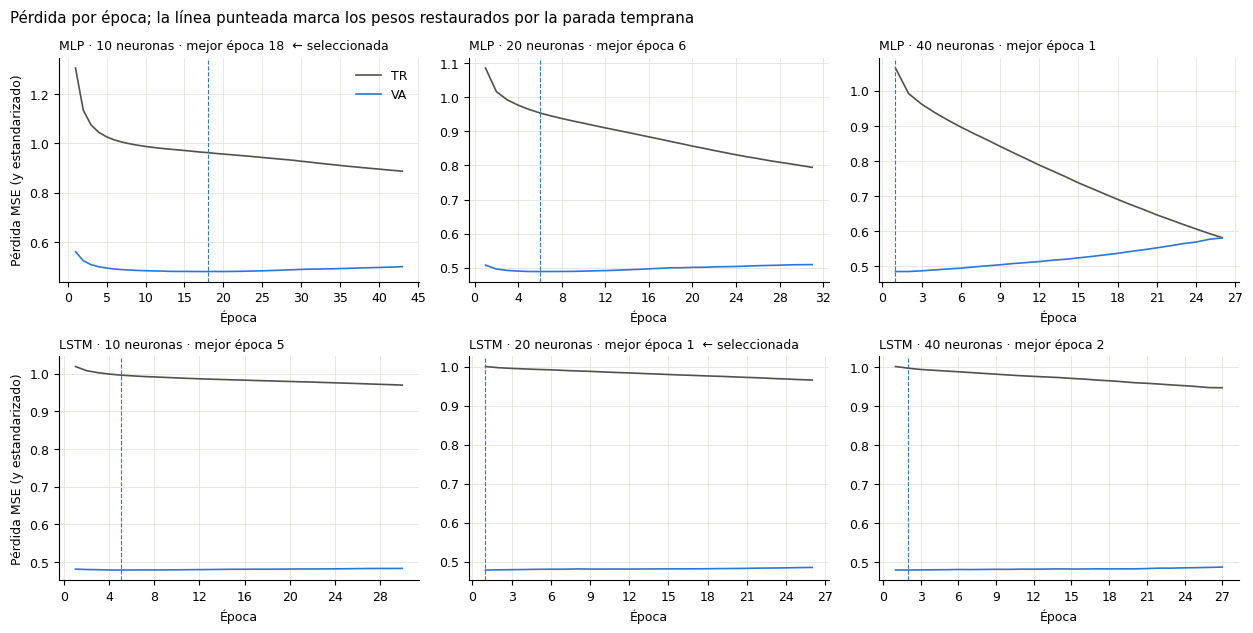

In [16]:
# === 7.1 Curvas de pérdida de TR y VA por época ===
from matplotlib.ticker import MaxNLocator
TINTA2, AZUL, REJILLA = '#52514e', '#2a78d6', '#e4e3df'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': REJILLA, 'grid.linewidth': 0.6, 'font.size': 9})
ncand = len(CONFIG['NEURONAS_CANDIDATAS'])
fig, axes = plt.subplots(2, ncand, figsize=(4.2 * ncand, 6.4), squeeze=False)
for i, red in enumerate(('mlp', 'lstm')):
    for j, n in enumerate(CONFIG['NEURONAS_CANDIDATAS']):
        c = CORRIDAS[f'cap8_{red}_n{n}_s{SEMILLA}']
        h, ax = c['hist'], axes[i, j]
        ax.plot(h.index, h['loss'], color=TINTA2, lw=1.2, label='TR')
        ax.plot(h.index, h['val_loss'], color=AZUL, lw=1.2, label='VA')
        ax.axvline(c['info']['mejor_epoca'], color=AZUL, ls='--', lw=0.8)
        marca = '  ← seleccionada' if n == MEJOR_N[red] else ''
        ax.set_title(f"{red.upper()} · {n} neuronas · mejor época {c['info']['mejor_epoca']}{marca}", loc='left', fontsize=9)
        ax.set_xlabel('Época'); ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        if j == 0:
            ax.set_ylabel('Pérdida MSE (y estandarizado)')
        if i == 0 and j == 0:
            ax.legend(frameon=False)
fig.suptitle('Pérdida por época; la línea punteada marca los pesos restaurados por la parada temprana', x=0.01, ha='left')
fig.tight_layout()
fig.savefig(DIRS['figuras'] / 'cap8_curvas_perdida_configuraciones.png', dpi=150, bbox_inches='tight')
plt.show()

## 8. Repetición de la mejor configuración con tres semillas

La corrida con semilla 42 ya existe y se reutiliza; se entrenan las otras dos semillas. Se reportan la media y la desviación estándar. Además, se evalúa el **ensamble de las tres semillas** (promedio de predicciones), que el libro sugiere para reducir la dependencia de la inicialización.

In [17]:
# === 8. Tres semillas ===
for red in ('mlp', 'lstm'):
    for s in CONFIG['SEMILLAS']:
        if f'cap8_{red}_n{MEJOR_N[red]}_s{s}' not in CORRIDAS:
            entrenar(red, MEJOR_N[red], s, 'repeticion_semillas')

SEMILLAS_DF = tabla_corridas([f'cap8_{r}_n{MEJOR_N[r]}_s{s}' for r in ('mlp', 'lstm') for s in CONFIG['SEMILLAS']])
RESUMEN_SEMILLAS = (SEMILLAS_DF.groupby('red')[['RMSE_TR', 'RMSE_VA', 'MAE_VA', 'prec_dir_VA', 'mejor_epoca']]
                    .agg(['mean', 'std']))
RESUMEN_SEMILLAS.to_csv(DIRS['resultados'] / 'resumen_semillas_cap8.csv')

ENSAMBLE = {}
filas_ens = []
for red in ('mlp', 'lstm'):
    ids = [f'cap8_{red}_n{MEJOR_N[red]}_s{s}' for s in CONFIG['SEMILLAS']]
    ENSAMBLE[red] = {c: np.mean([CORRIDAS[i]['pred'][c] for i in ids], axis=0) for c in ('TR', 'VA')}
    for conj in ('TR', 'VA'):
        df_c, y_c = REALES[conj]
        filas_ens.append({'id': f'cap8_{red}_n{MEJOR_N[red]}_ensamble3', 'capitulo': 8, 'modelo': f'{red}_ensamble3',
                          'tipo': 'ensamble_semillas', 'variables': f'{N} rezagos de rendimiento',
                          'configuracion': json.dumps({'promedio_de': ids}), 'neuronas': MEJOR_N[red],
                          'semilla': '/'.join(map(str, CONFIG['SEMILLAS'])), 'conjunto': conj,
                          'primer_objetivo': df_c.fecha_objetivo.min().date(), 'ultimo_objetivo': df_c.fecha_objetivo.max().date(),
                          'dispositivo': DISPOSITIVO, 'gpu': GPU_NOMBRE, **metricas(y_c, ENSAMBLE[red][conj]),
                          'tf_version': tf.__version__, 'fecha_ejecucion_utc': datetime.now(timezone.utc).isoformat(timespec='seconds')})
registrar_experimentos(filas_ens)

print('Media y desviación estándar con 3 semillas (mejor configuración de cada red):')
display(RESUMEN_SEMILLAS.round(6)) if 'display' in globals() else print(RESUMEN_SEMILLAS.round(6))
SEMILLAS_DF.round(6)

cap8_mlp_n10_s123      device:GPU:0 | épocas  33 (mejor   8) | params   331 |   11.9 s | RMSE TR 0.034732  VA 0.024605
cap8_mlp_n10_s2024     device:GPU:0 | épocas  44 (mejor  19) | params   331 |   14.7 s | RMSE TR 0.034314  VA 0.024577
cap8_lstm_n20_s123     device:GPU:0 | épocas  26 (mejor   1) | params  2201 |   13.9 s | RMSE TR 0.035068  VA 0.024258
cap8_lstm_n20_s2024    device:GPU:0 | épocas  26 (mejor   1) | params  2201 |   14.2 s | RMSE TR 0.035111  VA 0.024305
Media y desviación estándar con 3 semillas (mejor configuración de cada red):
       RMSE_TR             RMSE_VA              MAE_VA           prec_dir_VA  \
          mean       std      mean       std      mean       std        mean   
red                                                                            
lstm  0.035080  0.000027  0.024291  0.000028  0.017252  0.000035    0.511312   
mlp   0.034469  0.000229  0.024513  0.000136  0.017527  0.000106    0.509050   

               mejor_epoca            
      

,id,red,neuronas,semilla,params,epocas,mejor_epoca,tiempo_s,RMSE_TR,RMSE_VA,MAE_VA,prec_dir_VA,model_bias_VA
0,cap8_mlp_n10_s42,mlp,10,42,331,43,18,16.18,0.034361,0.024357,0.017406,0.504525,4.456790
1,cap8_mlp_n10_s123,mlp,10,123,331,33,8,11.88,0.034732,0.024605,0.017571,0.506787,1.907895
2,cap8_mlp_n10_s2024,mlp,10,2024,331,44,19,14.71,0.034314,0.024577,0.017604,0.515837,1.232323
3,cap8_lstm_n20_s42,lstm,20,42,2201,26,1,13.91,0.035062,0.024309,0.017284,0.511312,NaN
4,cap8_lstm_n20_s123,lstm,20,123,2201,26,1,13.93,0.035068,0.024258,0.017215,0.511312,NaN
5,cap8_lstm_n20_s2024,lstm,20,2024,2201,26,1,14.23,0.035111,0.024305,0.017258,0.511312,NaN


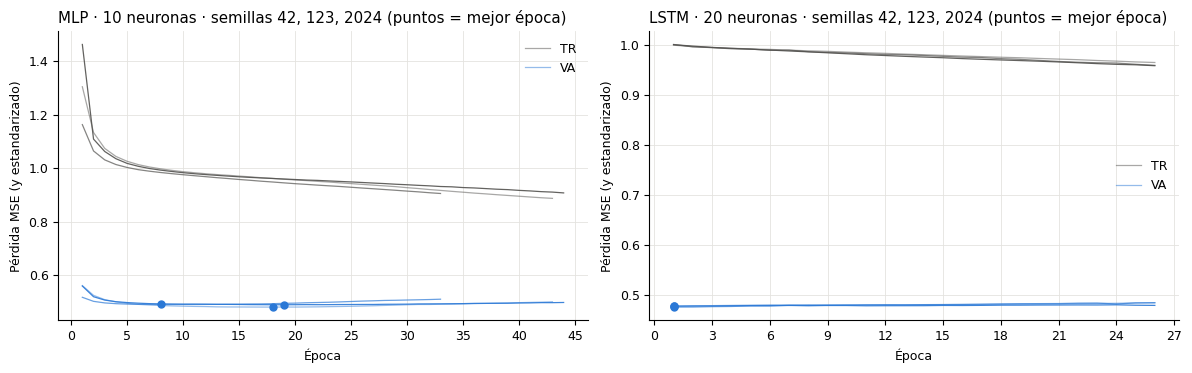

In [18]:
# === 8.1 Curvas de las tres semillas ===
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, red in zip(axes, ('mlp', 'lstm')):
    for k, s in enumerate(CONFIG['SEMILLAS']):
        c = CORRIDAS[f'cap8_{red}_n{MEJOR_N[red]}_s{s}']
        h = c['hist']
        ax.plot(h.index, h['loss'], color=TINTA2, lw=0.9, alpha=0.5 + 0.2 * k, label='TR' if k == 0 else None)
        ax.plot(h.index, h['val_loss'], color=AZUL, lw=0.9, alpha=0.5 + 0.2 * k, label='VA' if k == 0 else None)
        ax.plot(c['info']['mejor_epoca'], h.loc[c['info']['mejor_epoca'], 'val_loss'], 'o', color=AZUL, ms=5)
    ax.set_title(f"{red.upper()} · {MEJOR_N[red]} neuronas · semillas {', '.join(map(str, CONFIG['SEMILLAS']))} (puntos = mejor época)", loc='left')
    ax.set_xlabel('Época'); ax.set_ylabel('Pérdida MSE (y estandarizado)')
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(DIRS['figuras'] / 'cap8_curvas_perdida_semillas.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Modelos complementarios del capítulo 8 (opcional)

El libro también presenta una RNN simple y una CNN temporal (1D-CNN). Se entrenan una vez con la configuración del libro (20 unidades en la RNN; 64 filtros, kernel 4 y *pooling* 2 en la CNN), con la misma parada temprana. No son obligatorios. Si quieren omitirlos, pongan `MODELOS_COMPLEMENTARIOS_CAP8 = False`.

*Nota:* en el libro, el código de la RNN usa por error capas `Dense`. Aquí se usa `SimpleRNN`, que es lo que describe el texto.

In [19]:
# === 9. RNN y CNN temporal (configuración del libro) ===
if CONFIG['MODELOS_COMPLEMENTARIOS_CAP8']:
    entrenar('rnn', 20, SEMILLA, 'complementario_cap8', lote=16)
    entrenar('cnn', 64, SEMILLA, 'complementario_cap8', lote=8, max_epocas=100)
else:
    print('Modelos complementarios omitidos por configuración.')

cap8_rnn_n20_s42       device:GPU:0 | épocas  27 (mejor   2) | params   881 |   24.9 s | RMSE TR 0.034800  VA 0.024611
cap8_cnn_n64_s42       device:GPU:0 | épocas  30 (mejor   5) | params   833 |   31.1 s | RMSE TR 0.034538  VA 0.024560


## 10. Comparación con el capítulo 7 y selección con VA

Regla de selección, definida **antes** de ver el resultado:
1. Se compara el RMSE de VA de todos los candidatos. Para MLP y LSTM se usa el ensamble de tres semillas y se muestra la media ± desviación estándar de las corridas individuales.
2. Una red profunda solo se elige si su RMSE de VA es menor que el de la mejor referencia sencilla (cero o regresión lineal) **por más de una desviación estándar entre semillas**. Si no, la mejora no se distingue del ruido de la inicialización y se elige el modelo sencillo.
3. TE no interviene.

In [20]:
# === 10. Tabla comparativa en VA ===
filas_cmp = []
for nombre, m in REFERENCIAS.items():
    filas_cmp.append({'modelo': nombre, 'grupo': 'referencia cap. 7', **{k: m['VA'][k] for k in ('RMSE', 'MAE', 'prec_direccional', 'correlacion', 'model_bias')},
                      'RMSE_TR': m['TR']['RMSE'], 'RMSE_VA_std_semillas': np.nan})
if RUTA_EXP.exists():
    exp = pd.read_csv(RUTA_EXP)
    comp7 = exp[(exp.capitulo == 7) & (exp.conjunto == 'VA') & (exp.tipo == 'complementario_cap7')]
    tr7 = exp[(exp.capitulo == 7) & (exp.conjunto == 'TR')].set_index('modelo')['RMSE']
    for _, r in comp7.iterrows():
        filas_cmp.append({'modelo': r['modelo'], 'grupo': 'complementario cap. 7', 'RMSE': r['RMSE'], 'MAE': r['MAE'],
                          'prec_direccional': r['prec_direccional'], 'correlacion': r['correlacion'],
                          'model_bias': r['model_bias'], 'RMSE_TR': tr7.get(r['modelo'], np.nan), 'RMSE_VA_std_semillas': np.nan})
for red in ('mlp', 'lstm'):
    m_va, m_tr = metricas(y_va, ENSAMBLE[red]['VA']), metricas(y_tr, ENSAMBLE[red]['TR'])
    std = SEMILLAS_DF[SEMILLAS_DF.red == red]['RMSE_VA'].std(ddof=1)
    filas_cmp.append({'modelo': f'{red}_ensamble3 ({MEJOR_N[red]} neuronas)', 'grupo': 'red profunda cap. 8',
                      **{k: m_va[k] for k in ('RMSE', 'MAE', 'prec_direccional', 'correlacion', 'model_bias')},
                      'RMSE_TR': m_tr['RMSE'], 'RMSE_VA_std_semillas': std,
                      'RMSE_VA_media_semillas': SEMILLAS_DF[SEMILLAS_DF.red == red]['RMSE_VA'].mean()})
for rid, c in CORRIDAS.items():
    if c['VA']['tipo'] == 'complementario_cap8':
        filas_cmp.append({'modelo': f"{c['red']} (libro)", 'grupo': 'complementario cap. 8',
                          **{k: c['VA'][k] for k in ('RMSE', 'MAE', 'prec_direccional', 'correlacion', 'model_bias')},
                          'RMSE_TR': c['TR']['RMSE'], 'RMSE_VA_std_semillas': np.nan})
COMPARACION = pd.DataFrame(filas_cmp).rename(columns={'RMSE': 'RMSE_VA', 'MAE': 'MAE_VA', 'prec_direccional': 'prec_dir_VA',
                                                      'correlacion': 'correlacion_VA', 'model_bias': 'model_bias_VA'})
COMPARACION = COMPARACION.sort_values('RMSE_VA').reset_index(drop=True)
COMPARACION.to_csv(DIRS['resultados'] / 'comparacion_modelos_cap8_VA.csv', index=False)
COMPARACION.round(6)

,modelo,grupo,RMSE_VA,MAE_VA,prec_dir_VA,correlacion_VA,model_bias_VA,RMSE_TR,RMSE_VA_std_semillas,RMSE_VA_media_semillas
0,sgd,complementario cap. 7,0.024226,0.017269,0.533937,0.087109,2.400000,0.034959,NaN,NaN
1,regresion_lineal,referencia cap. 7,0.024258,0.017276,0.502262,0.072848,3.018182,0.034892,NaN,NaN
2,lstm_ensamble3 (20 neuronas),red profunda cap. 8,0.024286,0.017242,0.511312,0.029248,NaN,0.035073,0.000028,0.024291
3,mlp_ensamble3 (10 neuronas),red profunda cap. 8,0.024322,0.017314,0.502262,0.035560,3.804348,0.034219,0.000136,0.024513
4,cero,referencia cap. 7,0.024342,0.017219,NaN,NaN,NaN,0.035180,NaN,NaN
5,cnn (libro),complementario cap. 8,0.024560,0.017484,0.513575,-0.023679,1.711656,0.034538,NaN,NaN
6,rnn (libro),complementario cap. 8,0.024611,0.017540,0.515837,-0.017359,4.972973,0.034800,NaN,NaN
7,bosque,complementario cap. 7,0.024635,0.017702,0.477376,-0.011797,2.593496,0.020561,NaN,NaN
8,adaboost,complementario cap. 7,0.025281,0.018542,0.522624,0.029716,3.652632,0.032705,NaN,NaN
9,knn,complementario cap. 7,0.025723,0.018586,0.479638,-0.014826,1.376344,0.032592,NaN,NaN


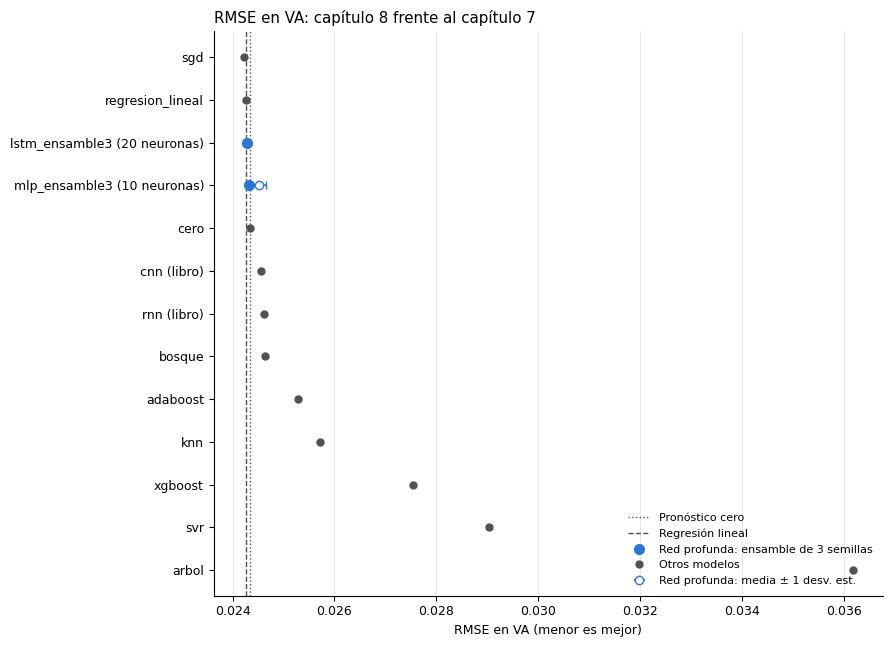

In [21]:
# === 10.1 Gráfica: RMSE de VA por modelo ===
cmp = COMPARACION.sort_values('RMSE_VA', ascending=False).reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 0.38 * len(cmp) + 1.6))
for i, r in cmp.iterrows():
    profunda = r['grupo'] == 'red profunda cap. 8'
    if profunda and np.isfinite(r['RMSE_VA_std_semillas']):
        m = r['RMSE_VA_media_semillas']
        ax.errorbar(m, i, xerr=r['RMSE_VA_std_semillas'], fmt='o', mfc='white', mec=AZUL, ecolor=AZUL,
                    elinewidth=1.2, capsize=3, ms=6, zorder=2)
    ax.plot(r['RMSE_VA'], i, 'o', color=AZUL if profunda else TINTA2, ms=7 if profunda else 5, zorder=3)
ax.axvline(REF_VA.loc['cero', 'RMSE'], color=TINTA2, ls=':', lw=1, label='Pronóstico cero')
ax.axvline(REF_VA.loc['regresion_lineal', 'RMSE'], color=TINTA2, ls='--', lw=1, label='Regresión lineal')
ax.plot([], [], 'o', color=AZUL, ms=7, label='Red profunda: ensamble de 3 semillas')
ax.errorbar([], [], xerr=[], fmt='o', mfc='white', mec=AZUL, ecolor=AZUL, capsize=3, label='Red profunda: media ± 1 desv. est.')
ax.plot([], [], 'o', color=TINTA2, ms=5, label='Otros modelos')
ax.set_yticks(range(len(cmp)), cmp['modelo'])
ax.set_xlabel('RMSE en VA (menor es mejor)')
ax.set_title('RMSE en VA: capítulo 8 frente al capítulo 7', loc='left')
ax.legend(frameon=False, loc='lower right', fontsize=8)
ax.grid(axis='y', visible=False)
fig.tight_layout()
fig.savefig(DIRS['figuras'] / 'cap8_comparacion_rmse_va.png', dpi=150, bbox_inches='tight')
plt.show()

In [22]:
# === 10.2 Selección justificada y configuración congelada ===
rmse_cero, rmse_lr = REF_VA.loc['cero', 'RMSE'], REF_VA.loc['regresion_lineal', 'RMSE']
mae_lr = REF_VA.loc['regresion_lineal', 'MAE']
mejor_simple = 'regresion_lineal' if rmse_lr < rmse_cero else 'cero'
rmse_simple = min(rmse_cero, rmse_lr)

print('¿Supera cada red a la regresión lineal en VA? (requisito del profesor)')
EVAL_REDES = {}
for red in ('mlp', 'lstm'):
    m = metricas(y_va, ENSAMBLE[red]['VA'])
    sem = SEMILLAS_DF[SEMILLAS_DF.red == red]
    std = sem['RMSE_VA'].std(ddof=1)
    margen = rmse_simple - m['RMSE']
    EVAL_REDES[red] = {'RMSE_VA_ensamble': m['RMSE'], 'MAE_VA_ensamble': m['MAE'],
                       'RMSE_VA_media_semillas': sem['RMSE_VA'].mean(), 'RMSE_VA_std_semillas': std,
                       'supera_LR_RMSE': bool(m['RMSE'] < rmse_lr), 'supera_LR_MAE': bool(m['MAE'] < mae_lr),
                       'margen_vs_mejor_simple': margen, 'mejora_mayor_que_ruido': bool(margen > std)}
    print(f"  {red.upper():4s} RMSE {m['RMSE']:.6f} vs LR {rmse_lr:.6f} → {'sí' if m['RMSE'] < rmse_lr else 'no'}  | "
          f"MAE {m['MAE']:.6f} vs LR {mae_lr:.6f} → {'sí' if m['MAE'] < mae_lr else 'no'}  | "
          f"margen vs {mejor_simple} = {margen:+.6f}, desv. semillas = {std:.6f}")

candidatas = {r: v for r, v in EVAL_REDES.items() if v['mejora_mayor_que_ruido']}
if candidatas:
    red_sel = min(candidatas, key=lambda r: candidatas[r]['RMSE_VA_ensamble'])
    SELECCION = {'modelo_seleccionado': f'{red_sel}_ensamble3', 'neuronas': MEJOR_N[red_sel],
                 'motivo': f'Menor RMSE de VA y su mejora sobre {mejor_simple} supera la variación entre semillas.'}
else:
    SELECCION = {'modelo_seleccionado': mejor_simple,
                 'motivo': ('Ninguna red mejora a la mejor referencia sencilla por más de una desviación estándar entre semillas; '
                            'por la regla definida antes de comparar, se mantiene el modelo sencillo.')}
red_continua = min(EVAL_REDES, key=lambda r: EVAL_REDES[r]['RMSE_VA_ensamble'])
SELECCION.update({
    'red_profunda_que_continua_al_cap9': red_continua, 'neuronas_red_continua': MEJOR_N[red_continua],
    'semillas': CONFIG['SEMILLAS'], 'evaluacion_redes_VA': EVAL_REDES,
    'referencias_VA': {'cero': {'RMSE': rmse_cero, 'MAE': REF_VA.loc['cero', 'MAE']}, 'regresion_lineal': {'RMSE': rmse_lr, 'MAE': mae_lr}},
    'configuracion_comun': {k: CONFIG[k] for k in ('PERDIDA', 'OPTIMIZADOR', 'TASA_APRENDIZAJE', 'LOTE', 'MAX_EPOCAS', 'PACIENCIA', 'N_REZAGOS')},
    'checkpoints': [CORRIDAS[f'cap8_{red_continua}_n{MEJOR_N[red_continua]}_s{s}']['info']['checkpoint'] for s in CONFIG['SEMILLAS']],
    'escaladores': ['modelos/escalador_cap7_rezagos20.joblib', 'modelos/escalador_y_cap8.joblib'],
    'TE_utilizado': False, 'fecha_utc': datetime.now(timezone.utc).isoformat(timespec='seconds'),
})
with open(DIRS['resultados'] / 'seleccion_cap8.json', 'w') as f:
    json.dump(SELECCION, f, indent=2, ensure_ascii=False, default=float)
print(f"\nSelección general con VA: {SELECCION['modelo_seleccionado']}")
print(f"Motivo: {SELECCION['motivo']}")
print(f"Red profunda que continúa al capítulo 9 (menor RMSE de VA entre MLP y LSTM): {red_continua.upper()} con {MEJOR_N[red_continua]} neuronas")

¿Supera cada red a la regresión lineal en VA? (requisito del profesor)
  MLP  RMSE 0.024322 vs LR 0.024258 → no  | MAE 0.017314 vs LR 0.017276 → no  | margen vs regresion_lineal = -0.000064, desv. semillas = 0.000136
  LSTM RMSE 0.024286 vs LR 0.024258 → no  | MAE 0.017242 vs LR 0.017276 → sí  | margen vs regresion_lineal = -0.000027, desv. semillas = 0.000028

Selección general con VA: regresion_lineal
Motivo: Ninguna red mejora a la mejor referencia sencilla por más de una desviación estándar entre semillas; por la regla definida antes de comparar, se mantiene el modelo sencillo.
Red profunda que continúa al capítulo 9 (menor RMSE de VA entre MLP y LSTM): LSTM con 20 neuronas


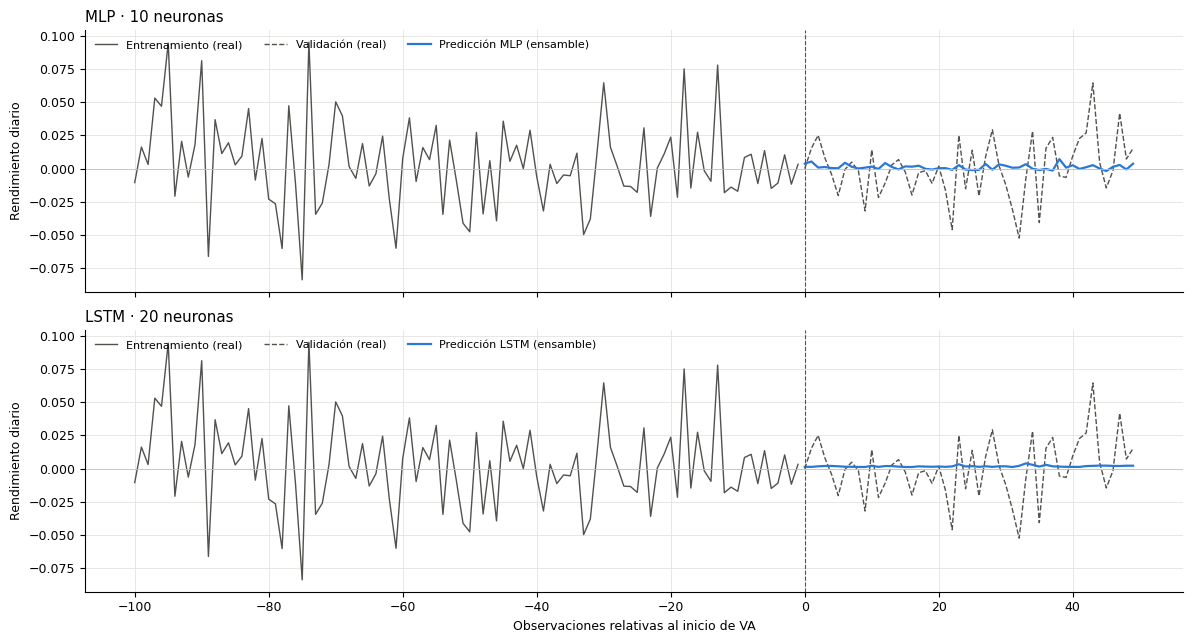

In [23]:
# === 10.3 Gráfica del libro: últimos valores de TR, primeros de VA y predicción del ensamble ===
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for ax, red in zip(axes, ('mlp', 'lstm')):
    ax.plot(np.arange(-100, 0), y_tr[-100:], color=TINTA2, lw=1.0, label='Entrenamiento (real)')
    ax.plot(np.arange(0, 50), y_va[:50], color=TINTA2, lw=1.0, ls='--', label='Validación (real)')
    ax.plot(np.arange(0, 50), ENSAMBLE[red]['VA'][:50], color=AZUL, lw=1.6, label=f'Predicción {red.upper()} (ensamble)')
    ax.axvline(0, color=TINTA2, ls='--', lw=0.8); ax.axhline(0, color='#c3c2b7', lw=0.6)
    ax.set_ylabel('Rendimiento diario'); ax.set_title(f'{red.upper()} · {MEJOR_N[red]} neuronas', loc='left')
    ax.legend(frameon=False, ncol=3, loc='upper left', fontsize=8)
axes[-1].set_xlabel('Observaciones relativas al inicio de VA')
fig.tight_layout()
fig.savefig(DIRS['figuras'] / 'cap8_train_val_redes.png', dpi=150, bbox_inches='tight')
plt.show()

## 11. Seguimiento: ¿una menor pérdida en TR también mejora VA? Sobreajuste o subajuste

In [24]:
# === 11. Diagnóstico de ajuste ===
diag = []
for rid, c in CORRIDAS.items():
    i = c['info']
    diag.append({'id': rid, 'red': c['red'], 'neuronas': c['neuronas'], 'semilla': c['semilla'],
                 'mejor_epoca': i['mejor_epoca'], 'epocas': i['epocas_entrenadas'],
                 'cambio_TR_tras_mejor_%': 100 * (i['perdida_TR_ultima_epoca'] / i['perdida_TR_mejor_epoca'] - 1),
                 'cambio_VA_tras_mejor_%': 100 * (i['perdida_VA_ultima_epoca'] / i['perdida_VA_mejor_epoca'] - 1),
                 'RMSE_TR': c['TR']['RMSE'], 'RMSE_VA': c['VA']['RMSE'],
                 'RMSE_TR_vs_cero_%': 100 * (c['TR']['RMSE'] / REFERENCIAS['cero']['TR']['RMSE'] - 1),
                 'RMSE_VA_vs_cero_%': 100 * (c['VA']['RMSE'] / REFERENCIAS['cero']['VA']['RMSE'] - 1)})
DIAG = pd.DataFrame(diag)
DIAG.to_csv(DIRS['resultados'] / 'diagnostico_ajuste_cap8.csv', index=False)

print('Después de la mejor época (hasta que se detuvo el entrenamiento):')
for red in DIAG.red.unique():
    d = DIAG[DIAG.red == red]
    print(f"  {red.upper():4s} pérdida TR {d['cambio_TR_tras_mejor_%'].mean():+.1f}% en promedio; "
          f"pérdida VA {d['cambio_VA_tras_mejor_%'].mean():+.1f}%")
busq = DIAG[DIAG.id.isin(BUSQUEDA.id)]
rho = busq[['RMSE_TR', 'RMSE_VA']].corr(method='spearman').iloc[0, 1] if len(busq) > 2 else np.nan
print(f'\nEntre las 6 configuraciones, correlación de Spearman entre RMSE de TR y de VA: {rho:+.2f}')
print('  (positiva: menor error en TR acompaña menor error en VA; negativa o cercana a 0: bajar TR no ayuda a VA)')
print('\nFrente al pronóstico cero del mismo conjunto (negativo = mejor que cero):')
print(DIAG.groupby('red')[['RMSE_TR_vs_cero_%', 'RMSE_VA_vs_cero_%']].mean().round(2).to_string())
print('\nLectura: si TR mejora mucho frente a cero pero VA no, hay SOBREAJUSTE (aprende particularidades de TR).')
print('Si ni TR ni VA mejoran frente a cero, hay SUBAJUSTE o falta de información útil en los 20 rezagos.')
DIAG.round(3)

Después de la mejor época (hasta que se detuvo el entrenamiento):
  MLP  pérdida TR -16.7% en promedio; pérdida VA +6.8%
  LSTM pérdida TR -3.9% en promedio; pérdida VA +1.2%
  RNN  pérdida TR -13.0% en promedio; pérdida VA +10.9%
  CNN  pérdida TR -6.0% en promedio; pérdida VA +3.5%

Entre las 6 configuraciones, correlación de Spearman entre RMSE de TR y de VA: -0.66
  (positiva: menor error en TR acompaña menor error en VA; negativa o cercana a 0: bajar TR no ayuda a VA)

Frente al pronóstico cero del mismo conjunto (negativo = mejor que cero):
      RMSE_TR_vs_cero_%  RMSE_VA_vs_cero_%
red                                       
cnn               -1.83               0.90
lstm              -0.37              -0.15
mlp               -1.93               0.71
rnn               -1.08               1.11

Lectura: si TR mejora mucho frente a cero pero VA no, hay SOBREAJUSTE (aprende particularidades de TR).
Si ni TR ni VA mejoran frente a cero, hay SUBAJUSTE o falta de información útil en l

,id,red,neuronas,semilla,mejor_epoca,epocas,cambio_TR_tras_mejor_%,cambio_VA_tras_mejor_%,RMSE_TR,RMSE_VA,RMSE_TR_vs_cero_%,RMSE_VA_vs_cero_%
0,cap8_mlp_n10_s42,mlp,10,42,18,43,-7.772,4.111,0.034,0.024,-2.328,0.063
1,cap8_mlp_n20_s42,mlp,20,42,6,31,-16.735,4.188,0.034,0.025,-3.161,0.911
2,cap8_mlp_n40_s42,mlp,40,42,1,26,-45.385,19.753,0.035,0.024,-0.425,0.534
3,cap8_lstm_n10_s42,lstm,10,42,5,30,-2.666,0.902,0.035,0.024,-0.467,-0.086
4,cap8_lstm_n20_s42,lstm,20,42,1,26,-3.469,1.385,0.035,0.024,-0.336,-0.135
5,cap8_lstm_n40_s42,lstm,40,42,2,27,-5.029,1.612,0.035,0.024,-0.525,-0.047
6,cap8_mlp_n10_s123,mlp,10,123,8,33,-7.976,4.015,0.035,0.025,-1.273,1.082
7,cap8_mlp_n10_s2024,mlp,10,2024,19,44,-5.415,1.740,0.034,0.025,-2.461,0.968
8,cap8_lstm_n20_s123,lstm,20,123,1,26,-4.168,1.833,0.035,0.024,-0.318,-0.344
9,cap8_lstm_n20_s2024,lstm,20,2024,1,26,-4.200,0.320,0.035,0.024,-0.197,-0.151


## 12. Controles finales del avance

In [25]:
# === 12. Verificación final del capítulo 8 ===
redes = [c for c in CORRIDAS.values() if c['red'] in ('mlp', 'lstm')]
controles = {
    'T4 verificada': bool(EVIDENCIA_T4.get('T4_OK')),
    'Todas las corridas con pesos en GPU': all('GPU' in c['info']['dispositivo_pesos'].upper() for c in CORRIDAS.values()),
    'Predicciones finitas': all(np.isfinite(p).all() for c in CORRIDAS.values() for p in c['pred'].values()),
    'Escaladores de X y de y ajustados solo con TR': bool(escalador.n_samples_seen_ == len(TR) and escalador_y.n_samples_seen_ == len(TR)),
    'Particiones idénticas al Avance 1': bool(PARTICION_VERIFICADA),
    'LSTM con forma ejemplos × pasos × variables': ENTRADAS['lstm']['TR'].ndim == 3 and ENTRADAS['lstm']['TR'].shape[1:] == (N, 1),
    'Tres configuraciones por red': all((BUSQUEDA.red == r).sum() == 3 for r in ('mlp', 'lstm')),
    'Tres semillas de la mejor configuración': all((SEMILLAS_DF.red == r).sum() == 3 for r in ('mlp', 'lstm')),
    'Parada temprana con pesos restaurados': all(c['info']['mejor_epoca'] <= c['info']['epocas_entrenadas'] for c in redes),
    'Checkpoints guardados en Drive': all((BASE / c['info']['checkpoint']).exists() for c in CORRIDAS.values()),
    'Pruebas controladas de errores correctas': bool(PRUEBAS_DF['correcto'].all()),
    'TE sin predicciones': all('TE' not in c['pred'] for c in CORRIDAS.values()),
}
for k, v in controles.items():
    print(('✔' if v else '✘'), k)
with open(DIRS['resultados'] / 'controles_cap8.json', 'w') as f:
    json.dump(controles, f, indent=2, ensure_ascii=False)
print('\nArchivos nuevos del capítulo 8 en Drive:')
for p in sorted(BASE.rglob('*')):
    if p.is_file() and ('cap8' in str(p) or p.name in ('experimentos.csv', 'pruebas_controladas_errores.csv', 'bitacora_errores.csv')):
        print('  ', p.relative_to(BASE))

✔ T4 verificada
✔ Todas las corridas con pesos en GPU
✔ Predicciones finitas
✔ Escaladores de X y de y ajustados solo con TR
✔ Particiones idénticas al Avance 1
✔ LSTM con forma ejemplos × pasos × variables
✔ Tres configuraciones por red
✔ Tres semillas de la mejor configuración
✔ Parada temprana con pesos restaurados
✔ Checkpoints guardados en Drive
✔ Pruebas controladas de errores correctas
✔ TE sin predicciones

Archivos nuevos del capítulo 8 en Drive:
   bitacora/bitacora_errores.csv
   figuras/cap8_comparacion_rmse_va.png
   figuras/cap8_curvas_perdida_configuraciones.png
   figuras/cap8_curvas_perdida_semillas.png
   figuras/cap8_train_val_redes.png
   modelos/cap8/cap8_cnn_n64_s42.keras
   modelos/cap8/cap8_lstm_n10_s42.keras
   modelos/cap8/cap8_lstm_n20_s123.keras
   modelos/cap8/cap8_lstm_n20_s2024.keras
   modelos/cap8/cap8_lstm_n20_s42.keras
   modelos/cap8/cap8_lstm_n40_s42.keras
   modelos/cap8/cap8_mlp_n10_s123.keras
   modelos/cap8/cap8_mlp_n10_s2024.keras
   modelos/ca

# ¿Una menor pérdida en TR mejora Va?

No. La correlación entre el RMSE de TR y el de VA en las 6 configuraciones es −0.66: las que más bajan el error en TR son las que más lo suben en VA.
Después de la mejor época, la pérdida de TR del MLP bajó 16.7% mientras la de VA subió 6.8%. En el MLP de 40 neuronas fue −45% contra +20%.

# Explicación del sobreajuste y subajuste observado

**MLP**: sobreajuste claro. Aprende particularidades de TR que no se repiten en VA, y entre más neuronas, peor.

**LSTM**: subajuste, o falta de información en los rezagos. Su mejor época es la 1 con las tres semillas. Su model bias sale “no definido” porque nunca predice una bajada: su predicción es casi constante y cercana a la media de TR (+0.16% diario), como se ve en la gráfica.

## 13. Preguntas del capítulo 8

- **Qué hicimos:** Entrenamos y evaluamos dos tipos de redes neuronales profundas: MLP y LSTM, utilizando los mismos 20 rendimientos rezagados de BTC/USDT del capítulo anterior. Se probaron tres configuraciones de neuronas (10, 20 y 40) para cada red, se utilizó la GPU T4 y se aplicó parada temprana para detener el entrenamiento cuando la pérdida de validación dejaba de mejorar. También se repitieron las mejores configuraciones con tres semillas diferentes para analizar la estabilidad de los resultados.
- **Por qué:** El objetivo fue determinar si las redes neuronales profundas pueden identificar patrones en los rendimientos históricos de Bitcoin y mejorar las predicciones frente a modelos de referencia más sencillos, como pronosticar cero o utilizar una regresión lineal.
- **Evidencia obtenida:** Se verificó correctamente el uso de la GPU T4, la alineación temporal de los datos, las particiones de entrenamiento, validación y prueba, y el ajuste de los escaladores únicamente con los datos de entrenamiento. Se probaron tres configuraciones por cada red y se repitieron las mejores con tres semillas. En validación, la regresión lineal obtuvo un RMSE de 0.024258 y un MAE de 0.017276. El MLP obtuvo un RMSE de 0.024322 y un MAE de 0.017314, mientras que el LSTM obtuvo un RMSE de 0.024286 y un MAE de 0.017242. Aunque el LSTM presentó un MAE ligeramente menor que la regresión lineal, ninguno de los dos modelos profundos consiguió superar la referencia en RMSE.
- **¿Una menor pérdida en TR también mejora VA?** No necesariamente. Los resultados muestran que, después de alcanzar la mejor época, la pérdida de entrenamiento disminuyó en promedio 16.7 % para MLP y 3.9 % para LSTM, mientras que la pérdida de validación aumentó 6.8 % y 1.2 %, respectivamente. Esto indica que seguir mejorando el ajuste sobre los datos de entrenamiento no garantiza una mejora en los datos de validación.
- **¿Sobreajuste o subajuste?** Se observan señales de sobreajuste, ya que la pérdida de entrenamiento continúa disminuyendo mientras que la pérdida de validación aumenta después de alcanzar su mejor resultado. Sin embargo, también se observa una capacidad predictiva limitada, debido a que las redes no consiguen superar consistentemente los modelos de referencia. Esto sugiere que los 20 rendimientos rezagados podrían no contener suficiente información para obtener mejores pronósticos.
- **Selección justificada:** De acuerdo con la regla de selección establecida previamente, se eligió la regresión lineal como modelo general, porque ninguna de las redes profundas consiguió mejorar el RMSE de la mejor referencia sencilla por más de una desviación estándar entre semillas. Aunque el LSTM presentó el menor RMSE entre las dos redes profundas, con 0.024286, su mejora no fue suficiente para justificar su selección frente al modelo sencillo. Se conserva el LSTM de 20 neuronas como la red profunda que continúa al capítulo 9 para su análisis posterior.
- **Qué cambiaríamos después:** En los siguientes capítulos probaríamos diferentes horizontes de predicción, ventanas expansivas y umbrales para generar señales de operación. También incorporaríamos indicadores técnicos, como medias móviles y volatilidad, para evaluar si aportan información adicional a los modelos. Finalmente, compararíamos los resultados considerando los costos de operación para determinar si las predicciones pueden convertirse en una estrategia financiera útil.